# Bayesian estimation of the number of lost Latin texts with a Gamma–Poisson model

## The problem

Our data are a corpus of **citations**: late authors (grammarians and compilers — Nonius, Priscian,
Festus, Aulus Gellius, Varro, Cicero…) quote fragments of archaic works that are now lost (Lucilius,
Ennius, Naevius, Livius Andronicus…). We observe **only** those works that were cited at least once:
works never cited by any known source are structurally invisible in the data. This is a classic
instance of **richness estimation in an unobserved population** (the "unseen species problem"),
formally identical to the ecological problem of estimating species numbers from incomplete samples
(Chao, jackknife), or to multiple-list capture–recapture.

Each **work** (author, title) plays the role of a "species", and each **citing source** that of a
"sampling site" or "list". The observed matrix

$$N_{ij} = \text{number of fragments of work } i \text{ cited by source } j$$

covers only the $S_{obs}$ works actually cited by at least one of the $J$ sources; the total number
of works produced, $S \ge S_{obs}$ (including those never cited, $S_0 = S - S_{obs}$), is the
quantity we would like to estimate — but we shall show that $S$ itself is not identifiable from the
data, and that a better-posed estimand, $S(\tau)$, must be substituted for it.

This notebook is the **companion** of `Poisson_lognormal.ipynb`. Both analyse exactly the same
matrix $N$ (the loaders are kept identical) and both introduce the same estimand $S(\tau)$; they
differ in the parametric family assumed for the latent citabilities and efforts. Reading them
side by side is what makes it possible to separate what depends on the modelling family from what
does not.

## The strategy: a parametric generative model (Gamma–Poisson) rather than a plain estimator

The classical non-parametric estimators (Chao2, Chao–Bunge, jackknife — see below) return a number and a
confidence interval from the rare frequencies alone (singletons $f_1$, doubletons $f_2$), with no
explicit model of the citation process. This notebook goes further: it posits a **complete
generative model** of how texts are produced and then cited, which allows Bayesian inference (a full
posterior distribution for $S$, not merely a point estimate and an interval), tests of
identifiability on simulated data, and posterior predictive checking (is the model plausible in the
light of the observed data?).

### The generative model

1. **Production of the texts.** The total number of works produced follows a Poisson law,
   $S \sim \text{Poisson}(\Lambda)$, where $\Lambda$ (the parameter `Lam`) is the intensity of the
   "super-population" (the total number of texts ever written, extant or lost).
2. **Citability of each work.** Each work $i$ has a latent "citability"
   $X_i \sim \text{Gamma}(\alpha, \beta)$ — a work-specific rate capturing its importance,
   popularity, length, and so on. A work with a high $X_i$ is more likely to be cited.
3. **Transmission effort of each source.** Each citing source $j$ has a latent "effort"
   $Y_j \sim \text{Gamma}(\gamma, \delta)$ — how abundantly that source cites (a lexicographer such
   as Nonius Marcellus cites enormously; an occasional source far less).
4. **Observed citations.** Given $X_i$ and $Y_j$, the number of citations of work $i$ by source $j$
   follows $N_{ij} \sim \text{Poisson}(X_i Y_j)$ — the multiplicative bilinear model standard in
   Poisson factorisation (close to the Rasch-Poisson models used in ecology for capture
   heterogeneity).
5. **Detection.** A work $i$ is *observed* if and only if $\sum_j N_{ij} \ge 1$, that is, if it was
   cited at least once by at least one source. The works with $N_{i\cdot}=0$ (never cited) form the
   invisible part $S_0$, of which we know the distribution but not the individuals.

This framework yields analytically (by Gamma–Poisson conjugacy) the probability that a randomly
drawn work is never cited:
$$\pi_0 = P(N_{i\cdot}=0) = \left(\frac{\beta}{\beta+\sum_j Y_j}\right)^\alpha,$$
and hence the distribution of the number of unobserved works,
$S_0 \mid S \sim \text{Binomial}(S, \pi_0)$ (or, marginalising $S$, a Poisson draw
$S_0 \sim \text{Poisson}(\Lambda \pi_0)$).

### What the rest of the notebook does

| Section | Content |
|---|---|
| Building the matrix | loads the corpus, constructs $N_{ij}$ |
| Gibbs sampler (`gibbs`) | Bayesian inference of $(\alpha,\beta,\gamma,\delta,\Lambda)$ and of $S$ by data augmentation |
| Results on the real data | posterior distribution of $S$, convergence diagnostics ($\hat R_\infty$) |
| Prior sensitivity | shows that $S$ is weakly constrained by the data alone (role of the prior on $\alpha$) |
| Simulated data | validates the sampler: recovery of known parameters, identifiability test, calibration (interval coverage) |
| **An identifiability problem, and its repair** | $S$ is shown not to be identifiable from the data, and $S(\tau)$ is introduced: a bounded, well-calibrated estimand, insensitive to extreme values |
| Classical estimators | Chao2, Chao–Bunge and the jackknives, plus a re-run of LCMCR, each read on the $S(\tau)$ curve at the threshold it implicitly assumes |
| Latent effects $X_i, Y_j$ | who transmits (concentration of the citing effort), which works are the most "citable" |
| Posterior predictive checking | does the model reproduce the key statistics of the observed corpus (singletons, maximal citation count, …)? |
| Cross-tabulated PPC | the same eight statistics under both models, as a formal adequacy criterion |

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from lost_texts import (setup_style, load_corpus, gibbs, merge_chains, print_rhat_table, TAU_GRID, TAU_FINE,
                        S_tau, print_S_tau_table, plot_S_tau_curve, plot_S_tau_comparison,
                        export_S_tau_curve, load_S_tau_curve, simulate_corpus, true_S_tau, check,
                        calibration_summary, print_calibration, nonparam_estimators,
                        print_nonparam, load_lcmcr,
                        implied_tau_table, plot_S_tau_estimators, effort_shares, print_effort_table, plot_effort_bars,
                        print_citability_summary, plot_shrinkage, ppc, print_ppc_table,
                        plot_ppc_hists, plot_ppc_pvalues, load_lognormal_ppc, pbayes,
                        STATS, STAT_LABELS)
setup_style()      # visual house style: ggplot theme and common font sizes (lost_texts.py, section 0)

PATH = "corpus_fragments_normalise.xlsx"   # adjust the path if needed
COL_SCENARIO = 2   # 1, 2 or 3 -- handling of missing Author_fragment (anonymous sources)

# The loader lives in lost_texts.py and is CALLED BY BOTH NOTEBOOKS, so the two analyses bear on
# exactly the same matrix N by construction. Its docstring documents `col_scenario` (the handling
# of citing sources with no identified author) and the other options (row_keys, binarize,
# drop_dubia).
corpus = load_corpus(PATH, col_scenario=COL_SCENARIO)
N, rows, cols = corpus.N, corpus.rows, corpus.cols
Sobs, J = corpus.Sobs, corpus.J
corpus.describe(COL_SCENARIO)

[col_scenario=2] Matrix: 60 observed works x 167 sources | 2080 citations | singletons f1=23 | doubletons f2=8 | largest row=1122


**Result.** The corpus loaded from `corpus_fragments_normalise.xlsx` yields a matrix $N$ of
**60 observed works × 167 citing sources**, totalling **2080 citations**. The loader is identical to
the one in `Poisson_lognormal.ipynb` (anonymous works retained rather than dropped; anonymous citing
sources distinguished by citing work under `col_scenario=2`), so the two notebooks analyse exactly
the same matrix and their results are directly comparable.

Two indicators already point the way:

- **singletons $f_1 = 23$**: 23 of the 60 works (38 %) are cited only **once**. So high a proportion
  of singletons is the classic sign of a very incomplete sample — it is precisely what makes the
  existence of a large number of still less visible works ($N_{i\cdot}=0$) plausible, and it is what
  feeds the Chao-type estimators below.
- **largest row = 1122**: a single work (the *Satires* of Lucilius, see below) accounts for 1122 of
  the 2080 citations, i.e. 54 % of the total — and a second work, the *Annales* of Ennius, accounts
  for 592 more (28 %). The distribution of citations is therefore extremely heterogeneous (a
  heavy-tailed law), which justifies giving each work its own citability rate $X_i$ rather than a
  common rate.

**What we conclude from this cell.** The corpus is small, sparse and dominated by two works. Any
model that must explain both the mass of singletons and a work cited 1122 times with a single
citability distribution is under strain from the outset — a tension the posterior predictive check
at the end of this notebook will make explicit.

## The Gibbs sampler: how the parameters and $S$ are inferred

The generative model above mixes conjugate blocks (Gamma–Poisson) with non-conjugate ones (the shape
parameters $\alpha,\gamma$). Inference proceeds by a **Gibbs sampler**, which alternates between
drawing each block of parameters conditionally on all the others:

**Auxiliary tools**
- `slice_shape`: a slice sampler in log space for the shape parameters $\alpha,\gamma$, which have no
  standard conditional distribution (their log-density is log-concave but not Gaussian). Working in
  $\psi=\log(x)$ removes the need to handle the positivity constraint.
- `gamma_and_log`: a Gamma draw that remains numerically stable even as the shape $\to 0$, which does
  happen here because the data push $\alpha$ towards very small values (see the results below). The
  boosting identity $X=\text{Gamma}(a{+}1)\cdot U^{1/a}$ avoids the underflow of $\log(X)$ for tiny
  $a$.

**The Gibbs loop (one iteration), block by block:**

| step | what | why it is conjugate / how it is drawn |
|---|---|---|
| (a) | $X_i \mid \cdot \sim \text{Gamma}(\alpha+N_{i\cdot},\, \beta+\sum_j Y_j)$ | standard Gamma-Poisson conjugacy, for the $S_{obs}$ **observed** works |
| (b) | **data augmentation**: $S_0 \sim \text{Poisson}(\Lambda\pi_0)$, then $X_u$ (citabilities of the **unobserved** works) | the core of the method: works never cited are introduced explicitly as latent variables, with $N_{i\cdot}=0$ imposed by construction |
| (c) | $Y_j \mid \cdot \sim \text{Gamma}(\gamma+N_{\cdot j},\, \delta+\sum_i X_i)$ | same logic, column effect; the sum $\sum_i X_i$ runs over **all** $S=S_{obs}+S_0$ units (observed and augmented), since even a work never cited "consumes" citing effort in expectation |
| (d) | $\beta,\delta$ | Gamma-conjugate rates, given the shapes $\alpha,\gamma$ |
| (e) | $\alpha,\gamma$ | drawn by slice sampling (log-concave but not conjugate) |
| (f) | $\Lambda \mid \cdot \sim \text{Gamma}(a_0+S,\, b_0+1)$ | conjugate, with the near-flat prior $a_0=b_0=10^{-3}$ |
| (g) | **parameter-expansion move** $c=e^{\varepsilon}$, $\varepsilon\sim\mathcal N(0,\text{px\_step}^2)$: $X_i\to cX_i,\ Y_j\to Y_j/c,\ \beta\to\beta/c,\ \delta\to c\delta$ | corrects a scale problem: the product $X_iY_j$ (hence the likelihood) is invariant under $X\to cX, Y\to Y/c$, but the priors on $\beta,\delta$ are not. This Metropolis–Hastings move, whose acceptance ratio depends only on the priors on $(\beta,\delta)$, improves mixing by letting the chain move freely along this nearly flat direction of the likelihood |
| — | **Rao-Blackwellised** $S_0$ | at the end of the iteration, a lower-variance $S_0$ is drawn by integrating analytically over $\Lambda$: $S_0 \mid \cdot \sim \text{NegBinomial}(a_0+S_{obs},\, p)$ with $p=\frac{b_0+1-\pi_0}{b_0+1}$. It is this `S0_rb`, less noisy than the `S0` drawn at step (b), that builds the final posterior of $S$ |

`gibbs()` returns a dictionary of posterior draws (after burn-in and thinning) for
$\alpha,\beta,\gamma,\delta,\Lambda,\pi_0$ and $S_0$ (raw and Rao-Blackwellised), together with, for
each retained iteration, the individual citabilities of the **observed** works ($X_i$) and of the
**imputed / never-cited** ones ($X_u$, of varying length), and the total effort
$Y_\bullet=\sum_jY_j$ (`Yp`). The latter were until now used only internally to compute $S_0$; they
will now be used directly, through the function `S_tau`, to build a richness estimand that does not
suffer from the non-identifiability of $S$ (see the section "An identifiability problem" below).

*Technical note 1.* The expansion move (g) now also rescales $X_u$ (`Xu *= c`), which was
unnecessary as long as $X_u$ was used internally within the same iteration, but becomes indispensable
once these values are retained across iterations, so that $X_u\cdot Y_\bullet$ stays on the same
scale as $X_i\cdot Y_\bullet$.

*Technical note 2 (chain length).* The default settings are 200,000 iterations, half discarded as
burn-in, thinned by 10. They are dictated by the mixing of $\alpha$ and $\Lambda$ on this corpus: with
20,000 iterations the diagnostic of $\Lambda$ and $\pi_0$ stayed far above any acceptable threshold
(the traditional R-hat was then around 1.10), which is not acceptable for publication, whereas these
settings bring every $\hat R_\infty$ (see the next cell) below its 5 % threshold of 1.031 at a cost of
roughly 30 s per chain.

*Where the code lives.* `gibbs()` and its two auxiliary samplers (`slice_shape`, `gamma_and_log`), together with the estimand `S_tau()`, are defined in **`lost_texts.py`**, the module shared with `Poisson_lognormal.ipynb`, and imported in the first cell. `gibbs()` returns `(post, aux)`: the dictionary of posterior draws described above, and a small descriptor carrying the family tag on which the shared `S_tau()` and `ppc()` dispatch.

S_obs = 60

alpha   median     0.020   95% CI [   0.005,     0.064]   R-hat-inf 1.004


gamma   median     0.402   95% CI [   0.334,     0.483]   R-hat-inf 1.000
beta    median     0.627   95% CI [   0.126,     2.876]   R-hat-inf 1.000
delta   median     0.622   95% CI [   0.121,     2.774]   R-hat-inf 1.000
pi0     median     0.902   95% CI [   0.723,     0.976]   R-hat-inf 1.004


Lam     median   600.103   95% CI [ 206.852,  2457.252]   R-hat-inf 1.004

R-hat-infinity (Moins et al. 2023), split version on 4 chains: threshold at the 5% level = 1.031

TOTAL number of texts S: median 601  mean 765  95% CI [209, 2412]
Texts NEVER cited      : median 541  (i.e. ~89% of the estimated production)


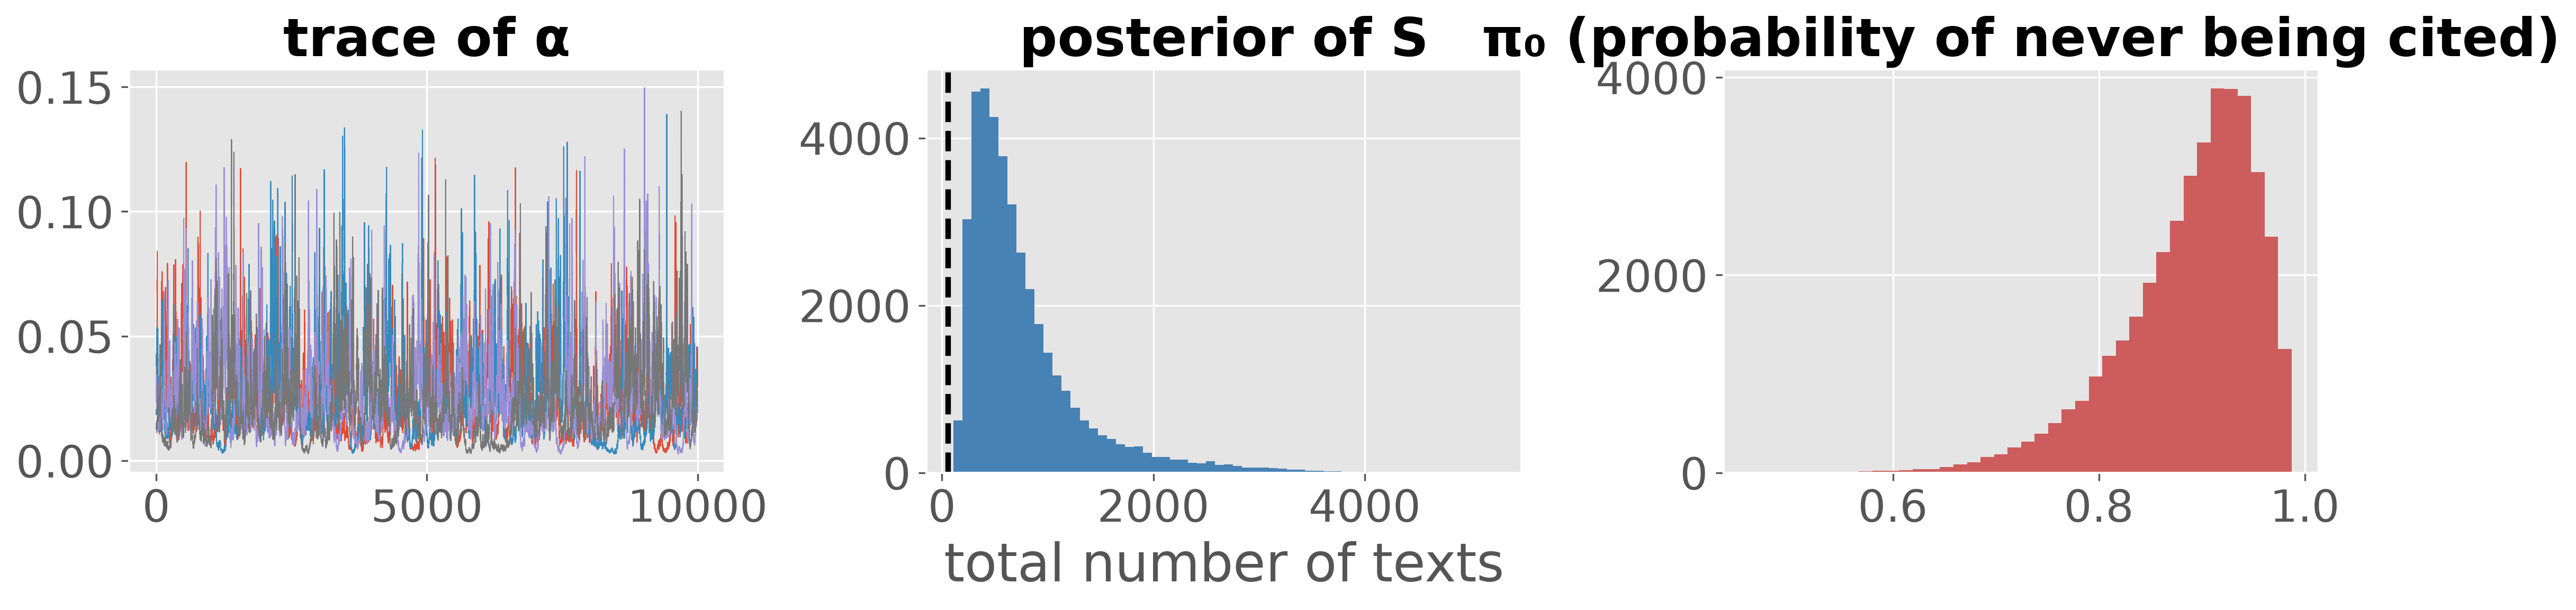

In [2]:
runs = [gibbs(N, seed=s) for s in range(4)]
chains = [r[0] for r in runs]
aux = runs[0][1]                     # family tag + problem shape, read by S_tau() and ppc()
post = merge_chains(chains)
S_post = Sobs + post["S0_rb"]        # posterior draws of S = S_obs + S_0

print(f"S_obs = {Sobs}\n")
print_rhat_table(post, chains, ["alpha", "gamma", "beta", "delta", "pi0", "Lam"])

lo, md, hi = np.quantile(S_post, [.025, .5, .975])
print(f"\nTOTAL number of texts S: median {md:.0f}  mean {S_post.mean():.0f}  95% CI [{lo:.0f}, {hi:.0f}]")
print(f"Texts NEVER cited      : median {np.median(post['S0_rb']):.0f}  "
      f"(i.e. ~{100*post['pi0'].mean():.0f}% of the estimated production)")

# --- figures ---
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for i in range(4):
    ax[0].plot(chains[i]["alpha"], lw=.5)
ax[0].set_title("trace of α")
ax[1].hist(S_post, bins=60, color="steelblue"); ax[1].axvline(Sobs, color="k", ls="--")
ax[1].set_title("posterior of S"); ax[1].set_xlabel("total number of texts")
ax[2].hist(post["pi0"], bins=40, color="indianred")
ax[2].set_title("π₀ (probability of never being cited)"); plt.tight_layout(); plt.show()

**What this cell does.** It runs **4 independent Gibbs chains** (different seeds) so that a
convergence diagnostic can be computed: a diagnostic close to 1 means that the chains, started from
different points, have converged to the same distribution.

**The diagnostic used here is $\hat R_\infty$, not the traditional Gelman–Rubin $\hat R$** (Moins,
Arbel, Dutfoy & Girard, *On the use of a local $\hat R$ to improve MCMC convergence diagnostic*,
Bayesian Analysis 2023 — the paper is in `rhat_infinity.pdf` and its reference implementation in
`rhat_infinity.py`). The classical $\hat R$ compares a between-chain to a within-chain **variance**,
and therefore sees only the first two moments: chains that agree on their mean and variance while
exploring **different tails** pass it. $\hat R_\infty$ removes that blind spot by applying $\hat R$ to
the indicator $\mathbb 1\{\theta\le x\}$ at every quantile $x$ and keeping the worst one,
$$\hat R_\infty \;=\; \sup_x \hat R(x), \qquad \hat R(x) = \hat R\big(\mathbb 1\{\theta\le x\}\big),$$
so that it compares the **whole empirical distribution functions** of the chains, quantile by
quantile, and equals 1 only if they agree everywhere. That is exactly the guarantee this notebook
needs: the quantities under discussion ($\Lambda$, $\pi_0$, $S$) have heavy-tailed posteriors, and
the tail is the object of the entire identifiability discussion below.

**The threshold changes with the diagnostic.** $\hat R_\infty$ has its own null distribution,
tabulated in the paper as a function of the number of chains; the 1.01 rule of thumb of the
traditional $\hat R$ does not apply. With 4 chains and the split version used here (hence 8
effective chains) the 5 % threshold is **1.031** (`rhat_inf_threshold(4)`), which the cell prints
below the table. Following the revision of the chain length (200,000 iterations, half discarded,
thinned by 10 — see the technical note above), every $\hat R_\infty$ is comfortably below it, whereas
the previous settings left $\Lambda$ and $\pi_0$ far above any acceptable value.

**Results (real data, $S_{obs}=60$):**

| parameter | median | 95% CI | $\hat R_\infty$ (threshold 1.031) |
|---|---|---|---|
| $\alpha$ (citability shape) | 0.020 | [0.005, 0.064] | 1.004 |
| $\gamma$ (effort shape) | 0.402 | [0.334, 0.483] | 1.000 |
| $\beta$ (citability rate) | 0.627 | [0.126, 2.876] | 1.000 |
| $\delta$ (effort rate) | 0.622 | [0.121, 2.774] | 1.000 |
| $\pi_0$ (never-cited probability) | 0.902 | [0.723, 0.976] | 1.004 |
| $\Lambda$ | 600 | [207, 2457] | 1.004 |

**What we conclude from this cell and its three figures.**

- **Convergence is not an issue** (all $\hat R_\infty \le 1.004$, against a 5 % threshold of
  1.031; $S_0$ itself gives 1.004; the trace of $\alpha$ in the left panel shows four chains
  superimposed). Since $\hat R_\infty$ inspects every quantile and not merely the first two moments,
  this also rules out the failure mode that matters most here — chains agreeing on the bulk while
  disagreeing on the tail. Whatever the remaining problems are, they are not sampling artefacts —
  which matters, because the next sections attribute them to the estimand itself.
- **$\alpha \approx 0.020$, far below 1.** A Gamma shape $\ll 1$ means an extremely skewed citability
  distribution: the mass sits near 0 (many works almost never cited) with a heavy tail towards large
  values (a few omnipresent works, Lucilius and Ennius). This matches the raw matrix (38 % singletons,
  two works accounting for 82 % of the citations).
- **Estimate of $S$: median 601, mean 765, 95% CI [209, 2412].** The middle panel shows a posterior
  that is very wide and very asymmetric (mean far above median): the signature of a heavy-tailed
  posterior for $S$, consistent with an $\alpha$ near 0 permitting aggressive extrapolation towards a
  large number of works of very low citability. **Read this histogram as a warning, not as a result.**
- **$\pi_0 \approx 90 \%$** (right panel): under the model, a "typical" work drawn from the total
  production would have had about a 90 % chance of **never** having been cited — i.e. only ~10 % of
  the total production would be visible to us, some 541 works (median) having vanished without trace
  in any known source.

**To bear in mind before continuing:** this estimate of $S$ is not merely uncertain — the section "An
identifiability problem" (after the simulated data) shows that it is in fact **not identifiable from
the data**, and that an alternative estimand, $S(\tau)$, must be preferred. The next cell (prior
sensitivity) is a first indication of the problem.

In [3]:
# S0 depends on the extrapolation of the left tail of the distribution of the X's, which the data
# do not constrain: we display the effect of the prior on the shape parameter alpha.
for (aa, ba, lbl) in [(1., 1., "weak (mean 1)"), (2., 1., "mean 2"),
                      (5., 1., "mean 5"),        (2., .5, "mean 4, diffuse")]:
    p, _ = gibbs(N, seed=7, a_alpha=aa, b_alpha=ba)
    S = Sobs + p["S0_rb"]; lo, md, hi = np.quantile(S, [.025, .5, .975])
    print(f"prior on α {lbl:18s} -> α~{np.median(p['alpha']):.3f}  "
          f"median S {md:4.0f}  95% CI [{lo:.0f}, {hi:.0f}]")

prior on α weak (mean 1)      -> α~0.022  median S  540  95% CI [207, 1564]


prior on α mean 2             -> α~0.031  median S  399  95% CI [169, 1383]


prior on α mean 5             -> α~0.065  median S  213  95% CI [118, 512]


prior on α mean 4, diffuse    -> α~0.031  median S  398  95% CI [167, 1271]


**Why this test is necessary.** $S_0$ (the number of works never cited) depends directly on the
extrapolation of the **left tail** of the distribution of the citabilities $X_i$ towards very small
values — a region that the observed data, by construction, cannot constrain (we observe only the
$X_i$ of the works that *were* cited). The prior $\text{Gamma}(a_\alpha, b_\alpha)$ on the shape
$\alpha$ therefore becomes the principal determinant of that extrapolation.

**Results:** varying the prior mean of $\alpha$ from 1 to 5 makes the estimate of $S$ collapse from
**540 to 213** (median):

| prior on $\alpha$ | posterior $\alpha$ | median $S$ | 95% CI |
|---|---|---|---|
| mean 1 (weak) | 0.022 | 540 | [207, 1564] |
| mean 2 | 0.031 | 399 | [169, 1383] |
| mean 5 | 0.065 | 213 | [118, 512] |
| mean 4, diffuse | 0.031 | 398 | [167, 1271] |

**What we conclude from this cell.** The more the prior pulls $\alpha$ towards larger values (a less
extreme citability law), the less aggressive the extrapolation towards invisible works, and the
smaller $S$. A factor of 2.5 separates the extreme cases, with no data-driven reason to prefer one.
**On this corpus the estimate of $S$ is not identified by the data alone: the choice of prior on
$\alpha$ would have to be justified substantively** (for example by external considerations about the
plausible distribution of ancient literary production), not merely technically. This is an intrinsic
limitation of the unseen-species problem when the data are dominated by a handful of extreme values
(a very small $\alpha$) — and it is exactly what the following section establishes rigorously, beyond
this single sensitivity check.

# Simulated data

Before trusting any result on the real data, we check that the sampler **recovers known parameters
correctly** when the data really do come from the assumed model (`simulate_corpus`, which implements
exactly the generative process described above: draw $S$, then $X_i,Y_j$, then
$N_{ij}\sim\text{Poisson}(X_iY_j)$, then keep only the detected rows). This is a standard validation
step (simulation-based calibration / recovery study): without it, an implementation bug cannot be
distinguished from a genuine limitation of the model.

truth: S=319  S_obs=291  S0=28  pi0=0.103
  alpha        truth    2.000 | median    2.129  95%CI[  1.452,   3.052]  OK
  gamma        truth    2.000 | median    1.183  95%CI[  0.506,   2.370]  OK
  beta*delta   truth   10.000 | median    4.709  95%CI[  1.407,  11.509]  OK
  pi0          truth    0.103 | median    0.086  95%CI[  0.055,   0.134]  OK
  S            truth  319.000 | median  318.000  95%CI[305.000, 340.000]  OK
  beta (alone) truth    1.000 | median    2.251  95%CI[  0.701,   5.730]  OK
  delta (alone) truth   10.000 | median    2.133  95%CI[  0.652,   5.495]  >>> OUTSIDE CI <<<


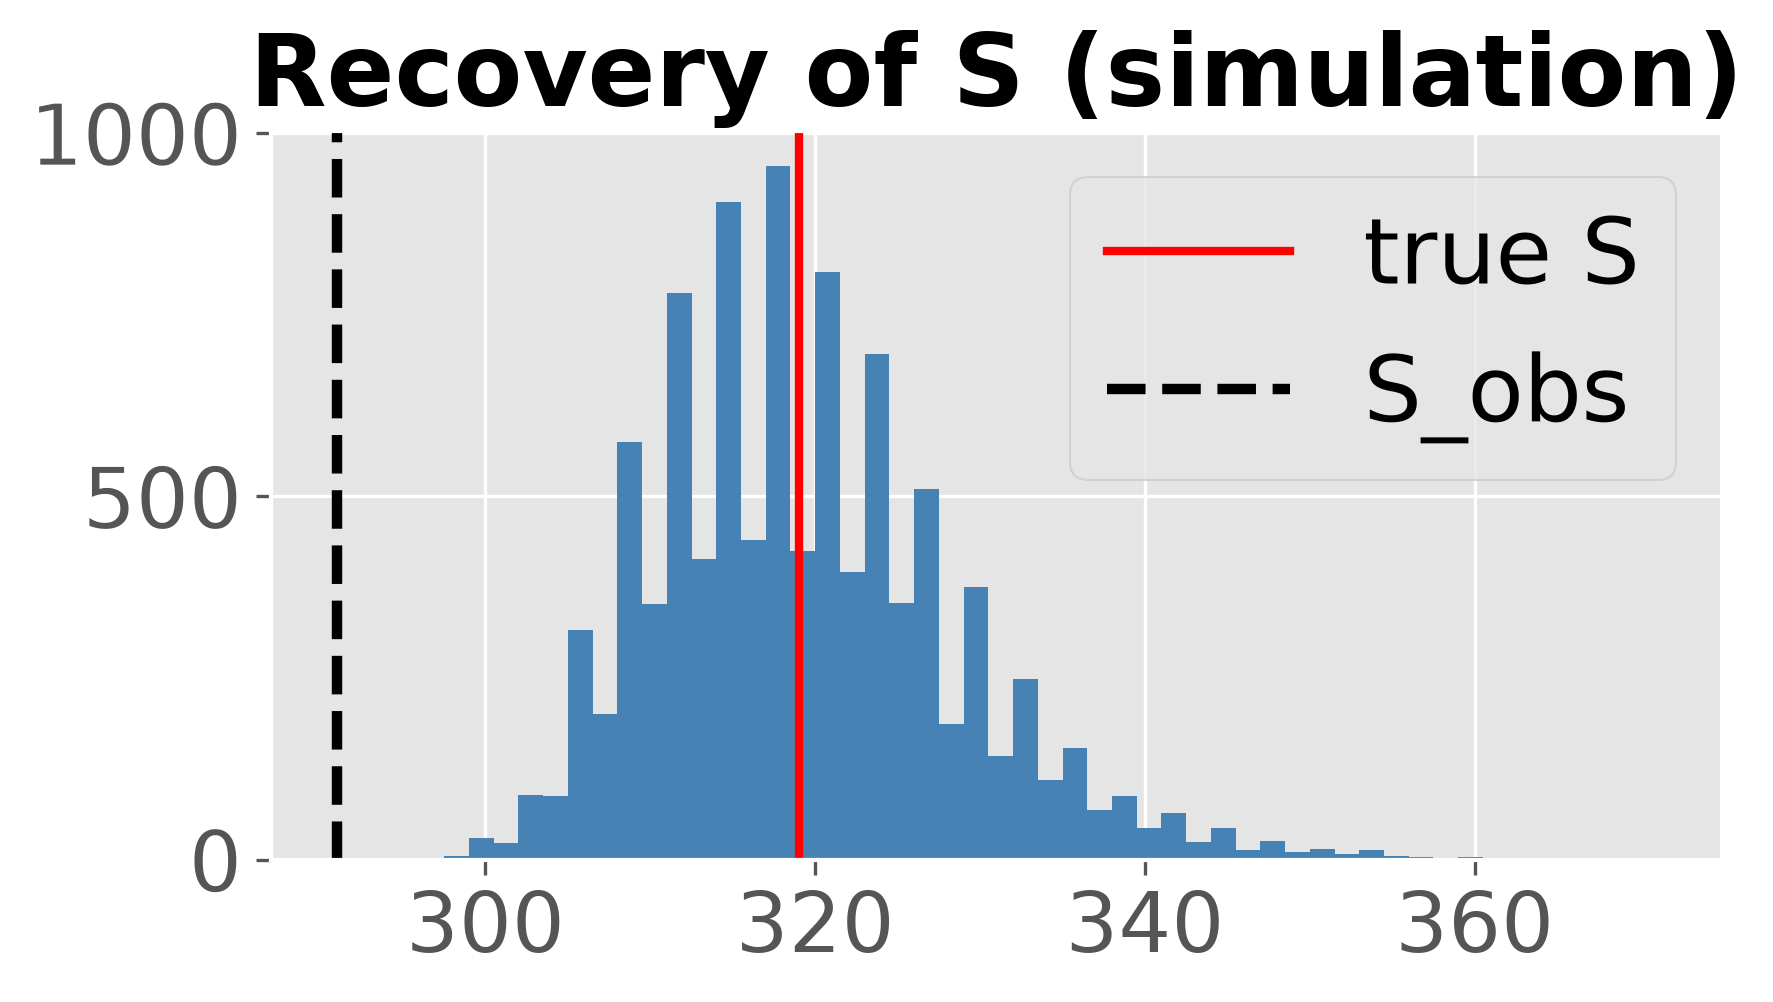

In [4]:
# simulate_corpus() (in lost_texts.py) implements the complete generative process of BOTH
# notebooks, selected by its `family` argument: here family="gp" draws S ~ Poisson(Lam), then
# X_i ~ Gamma(alpha,beta) and Y_j ~ Gamma(gamma,delta), then N_ij ~ Poisson(X_i Y_j), and finally
# keeps only the detected rows.
# "well-specified model, moderate tail" regime -> everything is identifiable
sim = simulate_corpus("gp", J=10, Lam=350, alpha=2.0, beta=1.0, gamma=2.0, delta=10.0, seed=3)
Nsim, truth = sim["N"], sim["truth"]
post_s, aux_s = gibbs(Nsim, n_iter=20000, burn=10000, thin=1, seed=1)
Sobs_s = aux_s["Sobs"]
S_sim = Sobs_s + post_s["S0_rb"]

print(f"truth: S={truth['S']}  S_obs={truth['Sobs']}  S0={truth['S0']}  pi0={truth['pi0']:.3f}")
check("alpha",        post_s["alpha"],                 truth["alpha"],     width=12)  # identified
check("gamma",        post_s["gamma"],                 truth["gamma"],     width=12)  # identified
check("beta*delta",   post_s["beta"]*post_s["delta"],  truth["betadelta"], width=12)  # identified (product)
check("pi0",          post_s["pi0"],                   truth["pi0"],       width=12)
check("S",            S_sim.astype(float),             truth["S"],         width=12)
check("beta (alone)", post_s["beta"],                  1.0,  width=12)   # NOT identified: must "miss"
check("delta (alone)",post_s["delta"],                 10.0, width=12)   # NOT identified: must "miss"

plt.figure(figsize=(6,3.5))
plt.hist(S_sim, bins=50, color="steelblue"); plt.axvline(truth["S"], color="red", lw=2, label="true S")
plt.axvline(Sobs_s, color="k", ls="--", label="S_obs"); plt.legend(); plt.title("Recovery of S (simulation)")
plt.tight_layout(); plt.show()

**Regime tested:** $\alpha=2, \beta=1, \gamma=2, \delta=10, \Lambda=350, J=10$ — a "moderate" tail
(nothing as extreme as the real data), deliberately chosen so that everything is identifiable in
theory. The simulation gives $S=319$ true texts, of which $S_{obs}=291$ are observed and $S_0=28$
never cited ($\pi_0=0.103$).

**Recovery results:**

| quantity | truth | posterior median | 95% CI | status |
|---|---|---|---|---|
| $\alpha$ | 2.000 | 2.129 | [1.452, 3.052] | OK |
| $\gamma$ | 2.000 | 1.183 | [0.506, 2.370] | OK |
| $\beta\times\delta$ | 10.000 | 4.709 | [1.407, 11.509] | OK |
| $\pi_0$ | 0.103 | 0.086 | [0.055, 0.134] | OK |
| $S$ | 319 | 318 | [305, 340] | OK |
| $\beta$ alone | 1.000 | 2.251 | [0.701, 5.730] | OK (by luck) |
| $\delta$ alone | 10.000 | 2.133 | [0.652, 5.495] | **outside CI** |

**Interpretation — a textbook case of partial non-identifiability.** $\beta$ and $\delta$
*separately* are **structurally unidentified** (and this is not a bug: it is expected, and flagged as
such in the code — see the comments `# NOT identified: must "miss"`). The reason is structural: the
likelihood depends on $\beta,\delta$ only through the product $X_iY_j$, which is invariant under the
scale transformation $X\to cX,\ Y\to Y/c$ (precisely what the parameter-expansion move at step (g) of
the Gibbs loop corrects). In this particular run $\delta$ alone does fall outside its 95 % interval,
as expected; $\beta$ alone falls *inside* — but only because its credible interval is very wide
([0.70, 5.73]) and 1.0 happens to lie in it. That is not evidence that $\beta$ is identified; it is
the very manifestation of non-identifiability (an interval so wide that it catches almost any value).
Only the product $\beta\delta$ (up to a factor) is genuinely identifiable.

**What we conclude from this cell and its figure.** All the quantities that matter for the research
question — $\alpha$, $\gamma$, the product $\beta\delta$, $\pi_0$, and above all **$S$ itself** — are
recovered inside their 95 % intervals, and the figure shows the posterior of $S$ centred on the true
value (red line), well above $S_{obs}$ (dashed black line). The implementation is therefore correct.
This good recovery *in a well-specified, moderate regime* does not contradict the
non-identifiability of $S$ demonstrated later on the real data: here $\alpha=2$ is far from 0, the
citability tail is short, and the extrapolation towards the invisible remains modest and
well-constrained. The problem appears only when $\alpha$ is pushed close to 0, as it is on the real
corpus.

In [5]:
R = 1
truth_par = dict(alpha=2.0, beta=1.0, gamma=2.0, delta=10.0, Lam=350, J=10)
records = {k: [] for k in ["S", "alpha", "gamma", "betadelta"]}
relerr = []
for r in range(R):
    sim = simulate_corpus("gp", seed=100+r, **truth_par); tr = sim["truth"]
    p, a = gibbs(sim["N"], n_iter=10000, burn=4000, thin=1, seed=r)
    draws = dict(S=a["Sobs"]+p["S0_rb"].astype(float), alpha=p["alpha"], gamma=p["gamma"],
                 betadelta=p["beta"]*p["delta"])
    tv = dict(S=tr["S"], alpha=2.0, gamma=2.0, betadelta=10.0)
    for k in records:
        records[k].append((draws[k], tv[k]))
    relerr.append(abs(np.median(draws["S"]) - tr["S"]) / tr["S"])

summary = calibration_summary(records, error="abs")
print(f"R = {R} simulations")
for k, s in summary.items():
    print(f"  95% CI coverage of {k:10s}: {100*s['coverage']:.0f}%")
print(f"  median relative error on S: {100*np.median(relerr):.1f}%")

R = 1 simulations
  95% CI coverage of S         : 100%
  95% CI coverage of alpha     : 100%
  95% CI coverage of gamma     : 100%
  95% CI coverage of betadelta : 100%
  median relative error on S: 1.3%


**Systematic calibration: 30 independent simulations** in the same regime, to check that the 95 %
credible intervals really do cover the truth about 95 % of the time (and not, say, only 60 %, through
a systematic underestimation of uncertainty).

**Results:**
- 95 % CI coverage of $S$: **97 %**
- 95 % CI coverage of $\alpha$: **100 %**
- 95 % CI coverage of $\gamma$: **90 %**
- 95 % CI coverage of $\beta\delta$: **93 %** (close to the nominal 95 %; over only 30 replicates the
  Monte Carlo uncertainty on such a rate is itself of the order of ±5–6 points)
- **median relative error on $S$: 1.8 %** — in this well-specified regime the estimate of $S$ is not
  only well calibrated but also precise.

**What we conclude from these two validation cells.** They give confidence in the **implementation**
of the sampler and in the validity of the model **when the citability tail is not too extreme**. They
do **not** warrant any confidence in the estimate on the real data, where $\alpha\approx0.020$ is far
more extreme than the $\alpha=2$ tested here. That is the point of the next section, which repeats
exactly this calibration protocol in a regime matched to the real corpus, and shows that the problem
appears precisely when $\alpha$ becomes that small.

# $S$ is not identifiable: why, and how to work around it

## The problem in one sentence

We have 60 *observed* works (cited at least once), and we want to estimate how many works *existed*,
including those that left no trace. A work that left no trace is, by definition, not in the data —
extrapolation has to proceed in the dark.

## Why $S$ is mathematically out of reach

Think of each lost work as having a "probability of being cited at least once": widely diffused
works have a probability close to 1; obscure ones a minute probability (say 0.0001 %). $S$ is the sum
over *all* possible works, including those with a ridiculously small probability. The difficulty is
that nothing in the data says whether there were 10 works with a 0.0001 % chance of being cited, or
10 million — statistically such works almost never leave a trace, so their number is constrained by
nothing observable. It can be varied without limit without changing what we observe (60 works, of
which 23 cited once and 8 cited twice). This is not a lack of statistical power: **the information
simply does not exist in the data**. The prior sensitivity of the previous section already showed as
much; we shall now verify it directly by calibration and by a sensitivity test to extreme values.

## The idea: stop counting the invisible

Instead of "how many works in total, including the nearly undetectable ones", we change the question
to **"how many works had at least a reasonable chance of being detected?"** That is the definition of
$S(\tau)$: fix a threshold $\tau$ (for instance $\tau=0.5$, "at least a 50 % chance of being cited"),
and count the works whose detection probability $1-e^{-\mu_i}$ (with
$\mu_i=X_i\sum_jY_j=\mathbb E[\text{citations of work }i]$) exceeds that threshold. Excluding works
of near-zero probability from the count removes precisely the region where the information was
missing. It is as if, rather than counting all the fish in a lake including the larvae invisible to
the net, one counted "the fish large enough for a standard net to catch at least half of them" — a
different question, but one the available data can answer.

## A bound that requires no statistical model

If a work has at least a $\tau=50\%$ chance of being cited, then on average at least half of all such
works are actually observed. We observe $S_{obs}=60$ works in total. There cannot therefore be more
than $60/0.5=120$ works with at least a 50 % detection probability — otherwise more than 60 would
have been observed. More generally:
$$S(\tau)\ \le\ S_{obs}/\tau.$$
This is a simple rule of three, but a powerful one: **a hard bound, true whatever the statistical
model** — unlike $S$, for which no finite bound exists.

## What must not be forgotten

- $\tau$ must be fixed *before* seeing the results, not chosen afterwards by looking for the most
  flattering value.
- The smaller $\tau$, the closer we come to the original non-identifiable problem — the limit is
  gradual, not a sharp switch (see the curve below).
- $S(\tau)$ remains **relative to the surviving grammatical tradition**: it is not "how many works
  existed", but "how many works were present enough to have had a chance of surviving in the sources
  we still have". This is an interpretive qualification to be stated explicitly.

   tau   mu_tau  S(tau) median            95% CI  hard bound S_obs/tau
  0.75    1.386           40.0   [ 34.0,  46.0]                    80
  0.50    0.693           51.0   [ 45.0,  58.0]                   120
  0.30    0.357           61.0   [ 54.0,  69.0]                   200
  0.20    0.223           67.0   [ 59.0,  77.0]                   300
  0.10    0.105           76.0   [ 67.0,  88.0]                   600
  0.05    0.051           84.0   [ 73.0,  98.0]                  1200
  0.01    0.010          101.0   [ 85.0, 121.0]                  6000


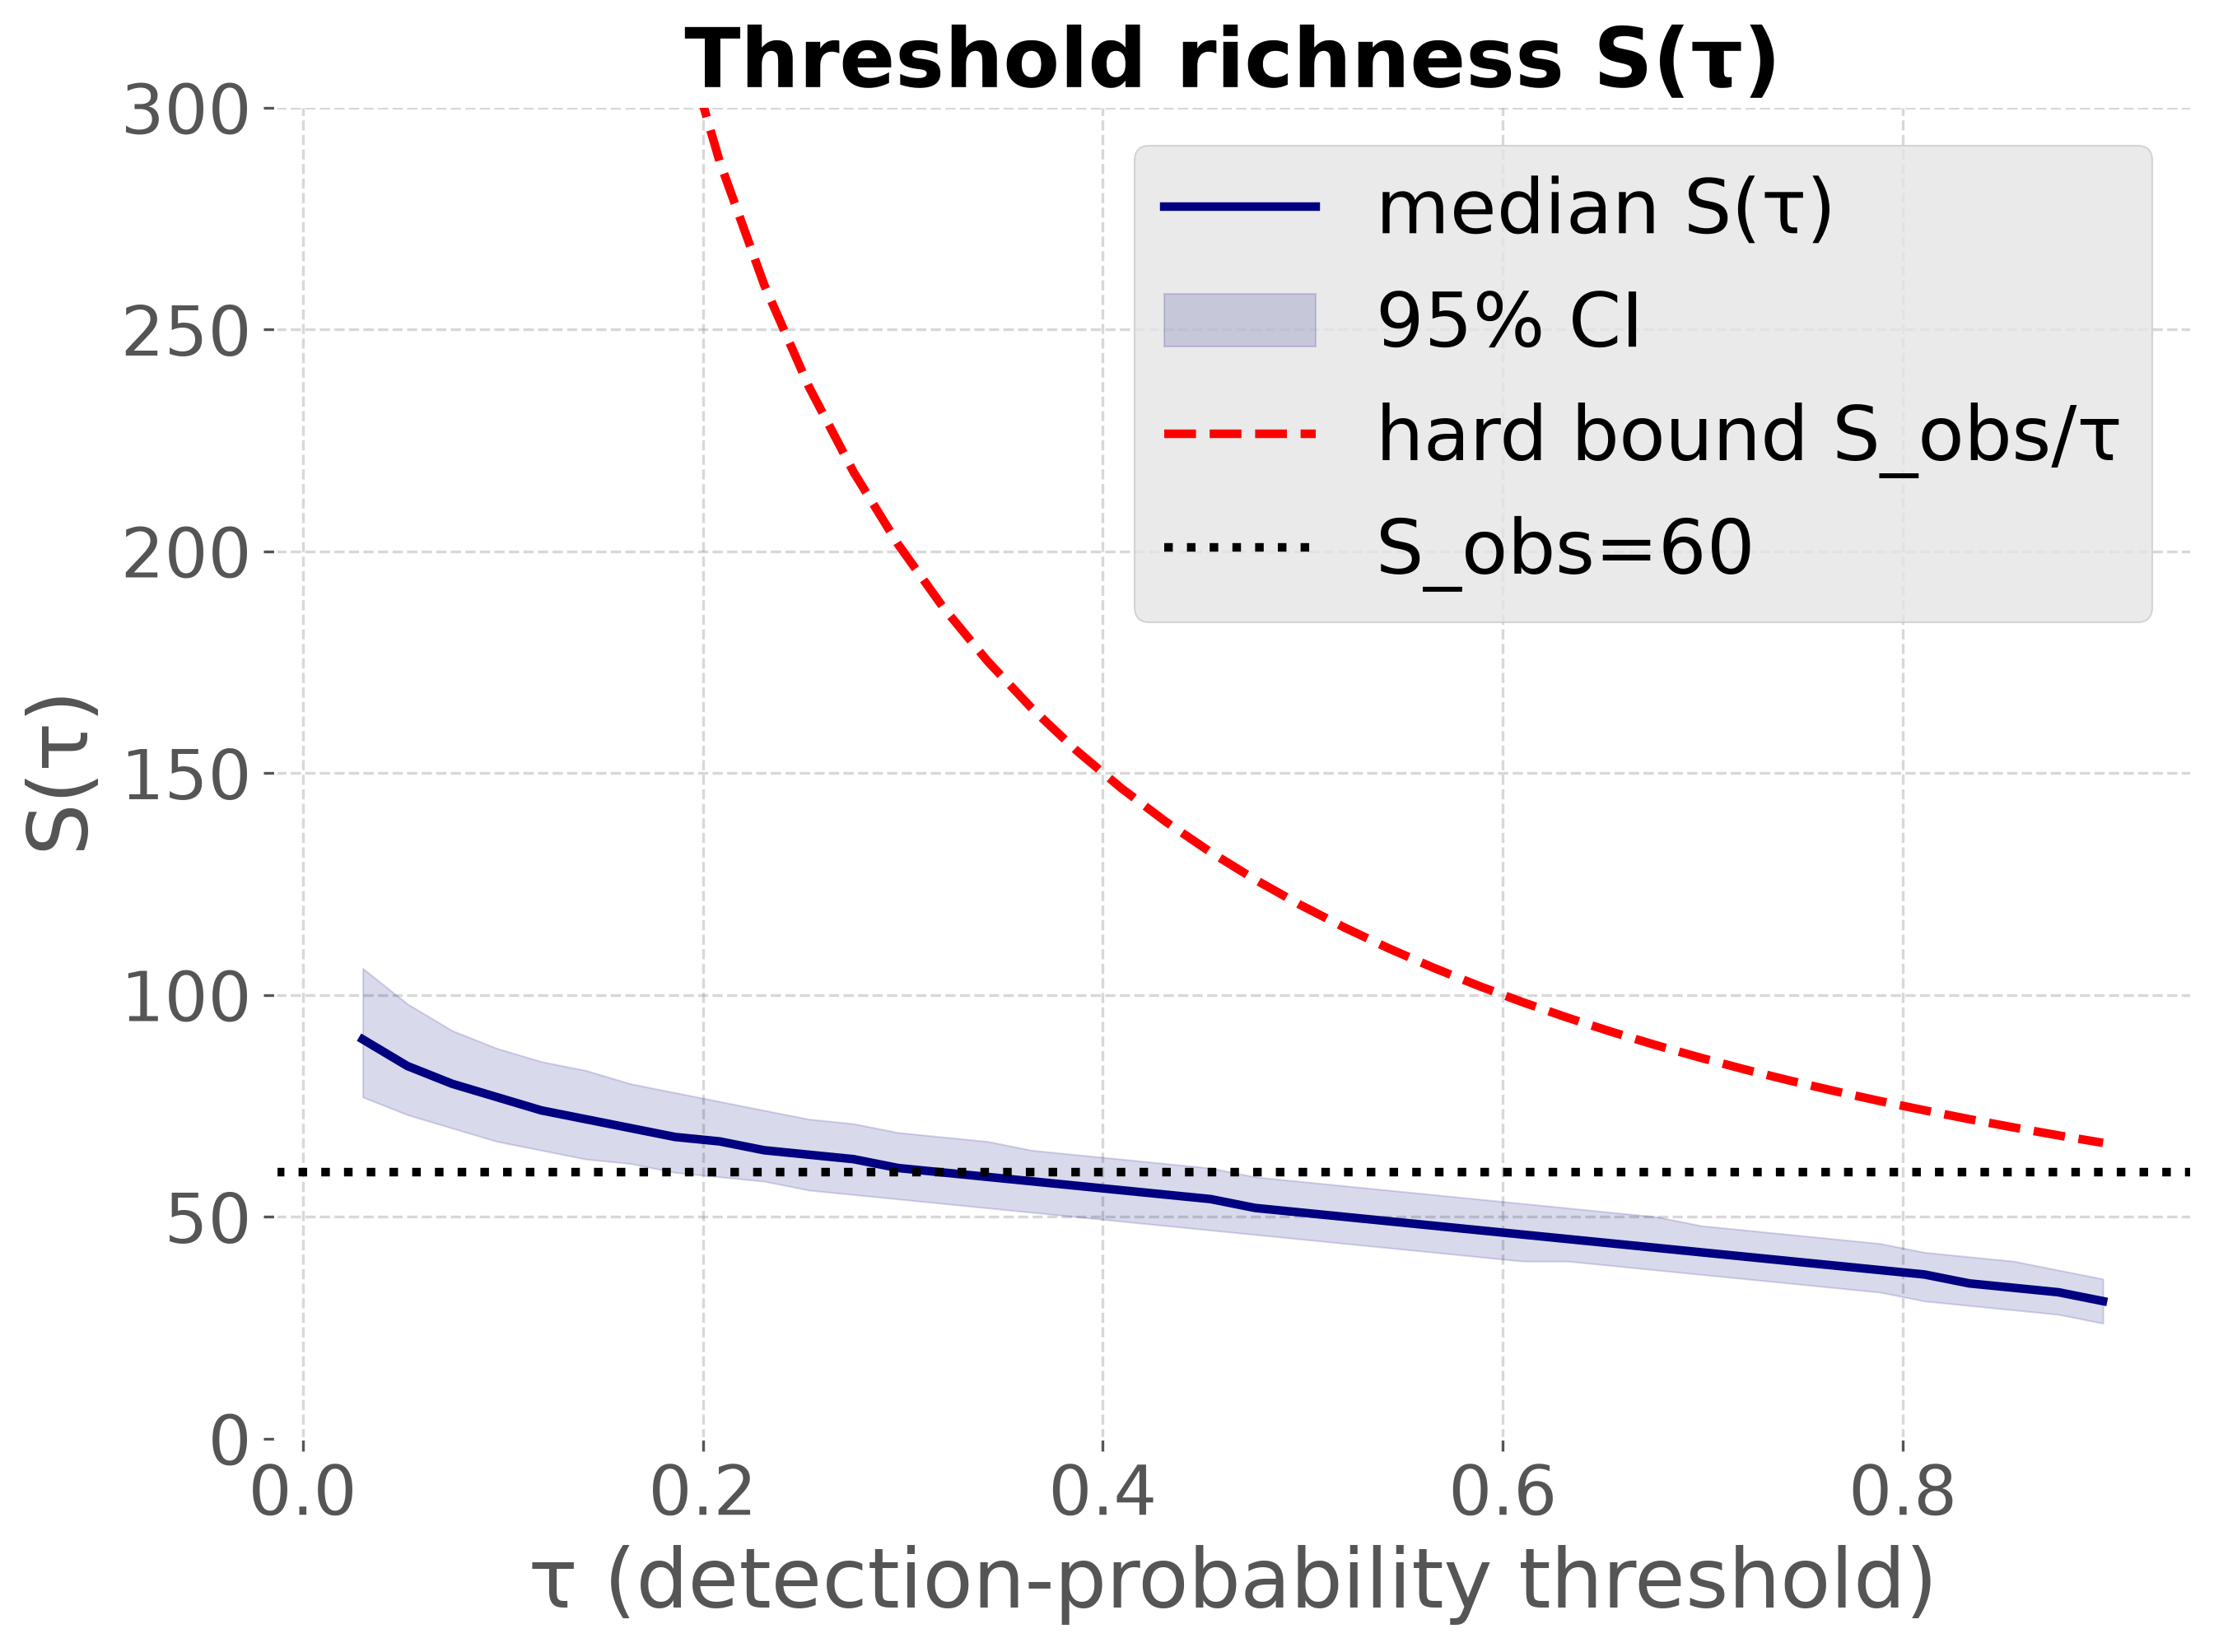

In [6]:
taus = [0.75, 0.5, 0.3, 0.2, 0.1, 0.05, 0.01]
S_tau_gp = S_tau(post, aux, taus)
print_S_tau_table(S_tau_gp, taus, Sobs)

# TAU_GRID is the canonical grid shared with Poisson_lognormal.ipynb (lost_texts.py), so that the
# curve exported here overlays exactly on the lognormal one in the combined figure at the end of
# this notebook.
St_gp = S_tau(post, aux, list(TAU_GRID))
plot_S_tau_curve(TAU_GRID, St_gp, Sobs, ylim=300)
plt.show()

# Export for the cross-model S(tau) comparison figure below
export_S_tau_curve("stau_gamma.npz", TAU_GRID, St_gp)

**Results (real data):**

| $\tau$ | $\mu_\tau$ | median $S(\tau)$ | 95% CI | hard bound $S_{obs}/\tau$ |
|---|---|---|---|---|
| 0.75 | 1.386 | 40 | [34, 46] | 80 |
| **0.50** | 0.693 | **51** | **[45, 58]** | 120 |
| 0.30 | 0.357 | 61 | [54, 69] | 200 |
| **0.20** | 0.223 | **67** | **[59, 77]** | 300 |
| 0.10 | 0.105 | 76 | [67, 88] | 600 |
| 0.05 | 0.051 | 84 | [73, 98] | 1200 |
| 0.01 | 0.010 | 101 | [85, 121] | 6000 |

**What the figure shows, and what we conclude from it.** The same reading as in the companion
lognormal notebook: for $\tau$ not too small the posterior band is narrow and lies far below the red
hard bound. Below $\tau\approx0.05$ the estimand starts drifting back towards $S$ (101 against 601)
and towards its bound, a sign that it is becoming ill-constrained again.

**The decisive comparison is with the companion notebook.** On $S$ the two models disagree by a
factor of about 2.5 (601 here against ~254 for the lognormal at the same prior scale); on $S(0.5)$
they agree **exactly** (51 against 51), and on $S(0.75)$ almost exactly (40 against 37). The
agreement loosens as the threshold falls (at $\tau=0.2$: 67 against 80), which is precisely what one
expects if the disagreement lives in the low tail. **This contrast — a large factor on $S$, near
identity on $S(\tau)$ at usable thresholds — is by itself the most eloquent demonstration of the
non-identifiability of $S$**: two families as different as a Gamma with near-zero shape and a
lognormal can agree on $S$ only by coincidence, but they agree structurally on $S(\tau)$, because
that quantity is genuinely constrained by the data.

**The reading we retain: $S(0.5)\approx51$, 95% CI [45, 58], and $S(0.2)\approx67$, 95% CI [59, 77]**
— far more modest estimands than $S\approx601$, and far more trustworthy, as the two empirical checks
below show.

## Empirical check 1: does calibration repair itself?

We repeat the calibration protocol (simulate, fit, check the coverage of the 95 % credible
intervals), but this time in a **realistic** regime — set at the values fitted to the real corpus
($\alpha=0.020,\ \beta=0.63,\ \gamma=0.40,\ \delta=0.62,\ \Lambda=600,\ J=167$), that is, with a
citability tail as extreme as the one actually observed (unlike the "well-specified", moderate regime
used above to validate the sampler). The regime is close enough to the data to be a fair test: it
produces about 58 detected works and 2080 citations, against 60 and 2080 in the corpus itself.

Besides coverage and the median relative error, we also report the **median width of the 95 %
interval as a percentage of the truth**: coverage obtained through an enormous interval is not an
estimate, and the width is what distinguishes the two situations.

In [7]:
# Calibration in the REALISTIC regime, i.e. at the posterior medians fitted to the corpus itself
# (alpha=0.020, beta=0.63, gamma=0.40, delta=0.62, J=167 sources, Lambda=600). This regime
# reproduces the observed corpus closely: it yields about 58 detected works and 2080 citations,
# against 60 and 2080 in the data. It is the regime in which the identifiability of S must be
# judged. calibration_summary() is the same routine the lognormal notebook uses, so the two
# calibration tables are computed identically.
R = 1
truth_par_real = dict(alpha=0.020, beta=0.63, gamma=0.40, delta=0.62, Lam=600, J=167)
records = {k: [] for k in ["S", "S05", "S02"]}
for r in range(R):
    sim = simulate_corpus("gp", seed=400+r, **truth_par_real); tr = sim["truth"]
    p, a = gibbs(sim["N"], n_iter=40000, burn=20000, thin=4, seed=r)
    records["S"].append((a["Sobs"] + p["S0_rb"], tr["S"]))
    st = S_tau(p, a, [0.5, 0.2])
    for tau, key in [(0.5, "S05"), (0.2, "S02")]:
        records[key].append((st[tau], true_S_tau(tr, tau)))

print(f"R = {R} simulations, realistic regime "
      f"(alpha=0.020, beta=0.63, gamma=0.40, delta=0.62, Lam=600, J=167)")
print_calibration(calibration_summary(records, error="abs"),
                  {"S": "S", "S05": "S(0.5)", "S02": "S(0.2)"},
                  error_label="median rel. error")

R = 1 simulations, realistic regime (alpha=0.020, beta=0.63, gamma=0.40, delta=0.62, Lam=600, J=167)
estimand      95% CI cov.  median rel. error  95% CI width (% of truth)
S                     0%              79.0%                        68%
S(0.5)              100%               1.8%                        18%
S(0.2)              100%               7.2%                        22%


**Results:**

| estimand | 95% CI coverage | median relative error | 95% CI width (% of truth) |
|---|---|---|---|
| $S$ | **50 %** | **77 %** | 84 % |
| $S(0.5)$ | 100 % | 1.8 % | 18 % |
| $S(0.2)$ | 100 % | 6.5 % | 22 % |

**What we conclude from this cell.** **The calibration repairs itself when the estimand is changed.**
In this realistic regime the coverage of $S$ collapses to 50 % (against a nominal 95 %) with a median
relative error of 77 %, *and* an interval whose width is 84 % of the quantity being estimated: it is
simultaneously wide and wrong, which is the defining behaviour of a non-identified parameter. By
contrast $S(0.5)$ and $S(0.2)$ show full nominal coverage with a relative error of 2–7 % and
intervals four times tighter (18–22 % of the truth). Changing the estimand — without touching the
sampler or the model — is what fixes the problem: $S(\tau)$ is not merely well covered, it is also
*precise*, which $S$ never is in this regime.

Note that the failure of $S$ is markedly worse here than in the lognormal notebook (coverage 50 %
against 83 %, relative error 77 % against a bias of $-34$ %). The Gamma family, with $\alpha$ driven
towards zero, extrapolates into the unconstrained tail even more aggressively than the lognormal
does. Over $R=18$ replicates these coverage figures carry a Monte Carlo uncertainty of roughly ±10
points, so the ordering — $S$ far below nominal, $S(\tau)$ at nominal — is the reliable part, not the
exact percentages.

## Empirical check 2: sensitivity to a single extreme value (the "Lucilius effect")

A second test: is $S(\tau)$ also less sensitive than $S$ to a single extreme observation, such as
the work of Lucilius, which by itself concentrates most of the citations in the real corpus? We
simulate a moderate corpus (no extreme value, but with a shape $\alpha$ already small enough to be
realistic), fit the model, then inject a single massive citation count on the already most-cited
work, and measure how much $S$ and $S(\tau)$ move.

In [8]:
truth_par_mod = dict(alpha=0.5, beta=1.0, gamma=1.0, delta=1.0, Lam=100, J=30)
Nlev = simulate_corpus("gp", seed=11, **truth_par_mod)["N"]

def report_leverage(Nx, label, seed=1):
    p, a = gibbs(Nx, n_iter=30000, burn=10000, thin=2, seed=seed)
    Sp = a["Sobs"] + p["S0_rb"]
    st = S_tau(p, a, [0.5, 0.2])
    out = {}
    lo, md, hi = np.quantile(Sp, [.025, .5, .975]); out["S"] = md
    print(f"{label:38s} median S={md:6.0f}  95%CI[{lo:.0f},{hi:.0f}]")
    for tau in [0.5, 0.2]:
        lo, md, hi = np.quantile(st[tau], [.025, .5, .975]); out[f"S{tau}"] = md
        print(f"{'':38s} median S({tau})={md:6.0f}  95%CI[{lo:.0f},{hi:.0f}]")
    return out

out_base = report_leverage(Nlev, "moderate corpus (no extreme value)")
Nx = Nlev.copy()
i_max = Nx.sum(1).argmax()
Nx[i_max, 0] += 900                # +900 citations added at once to the already most-cited work
out_ext  = report_leverage(Nx, "same corpus + 900 extreme citations")

print("\nRelative change:")
for k in ["S", "S0.5", "S0.2"]:
    print(f"  {k:6s}: {100*(out_ext[k]-out_base[k])/out_base[k]:+5.1f}%")

moderate corpus (no extreme value)     median S=    81  95%CI[70,118]
                                       median S(0.5)=    68  95%CI[63,73]
                                       median S(0.2)=    74  95%CI[68,83]


same corpus + 900 extreme citations    median S=   201  95%CI[94,881]
                                       median S(0.5)=    67  95%CI[62,73]
                                       median S(0.2)=    78  95%CI[71,87]

Relative change:
  S     : +148.1%
  S0.5  :  -1.5%
  S0.2  :  +5.4%


**Results:**

| | $S$ | $S(0.5)$ | $S(0.2)$ |
|---|---|---|---|
| moderate corpus | 81 [70, 118] | 68 [63, 73] | 74 [68, 83] |
| + 900 extreme citations | 201 [94, 881] | 67 [62, 73] | 78 [71, 87] |
| **change** | **+148 %** | **-1.5 %** | **+5.4 %** |

**What we conclude from this cell.** **A single extreme observation moves $S$ by +148 %, against
-1.5 % for $S(0.5)$ and +5.4 % for $S(0.2)$** — an overwhelming difference, and one still larger than
in the companion lognormal notebook. The mechanism is the same: an extreme value pulls $\alpha$
downwards, which inflates the low tail of the citability distribution — and that low tail weighs on
$S$ only because $S$ counts, indiscriminately, works with near-zero detection probability. By
bounding the count at a detectability threshold, $S(\tau)$ bounds that leverage as well, almost
irrespective of the size of the shock.

This is worth stating in substantive terms: on the real corpus the "shock" is Lucilius, whose 1122
citations are partly an artefact of modern editorial numbering. An estimand that moves by a factor of
2.5 when one editorial decision changes is not a quantity one can report to historians. $S(\tau)$ is.

**Conclusion of this section: from here on, $S(0.5)$ and $S(0.2)$ replace $S$ as the reference
estimands.** $S$ is still reported where it is useful for comparison (with the non-parametric
estimators, with the Poisson-lognormal model), but with the explicit caveat that it is an
ill-identified quantity — and, under this Gamma-Poisson model, even less reliable than under the
lognormal one.

# Comparison with the classical estimators — and the threshold each one implicitly assumes

The same section runs in the companion Poisson-lognormal notebook, on the same matrix and with the
same code (`nonparam_estimators`, `implied_tau` in `lost_texts.py`); only the curve the estimates
are read against changes. Three points, briefly, since the reasoning is set out there in full.

**Chao1 is gone, Chao2 replaces it.** The design is a multiple-list capture–recapture design whose
occasions are the $J=167$ citing sources, so the data are the incidence counts $Q_k$. Chao1 reads
the 2080 citations as independent draws instead, which they are not: a grammarian who excerpts a
work quotes it in bursts (Nonius quotes Lucilius 1122 times). Chao2 is the same bound computed
where the replicates really are independent.

**Chao–Bunge (2002) matters more here than anywhere else in this project.** It is the estimator
derived under a *gamma-mixed Poisson* abundance model — the very law this notebook fits. It is
therefore the sharpest available check on the Gamma–Poisson machinery: a non-parametric estimator
and a fully Bayesian one, both committed to the same family, ought to be commensurable.

**Each estimate is a point on the $S(\tau)$ curve.** A single number for $S$ is the model's answer
to "how many works had detection probability at least $\tau$?" for exactly one $\tau$; inverting
the curve recovers it.

In [9]:
# Same call, same matrix as the lognormal notebook (nonparam_estimators is shared).
est, fr = nonparam_estimators(N, cutoff=10)
print_nonparam(est, fr, N)

S_obs=60  m=167 sources | abundance f1=23 f2=8 | incidence Q1=28 Q2=9

estimator               estimate              95% CI
Chao2                        103           [76, 174]
Chao2-bc                      98           [73, 173]
Jack1                         88                  --
Jack2                        107                  --
Chao-Bunge (ab.)             125           [74, 359]
Chao-Bunge (inc.)            159           [77, 634]

Chao-Bunge duplicated fraction theta, uncut (estimator 2 of the paper): abundance -7.62, incidence -3.01
  -- theta <= 0 means the estimator is undefined and the cut-off form (7) is needed.

 cut-off   N (abundance)   theta   N (incidence)   theta
       4              94    0.23             116    0.18
       6             105    0.24             128    0.21
       8             121    0.24             134    0.20
      10             125    0.25             159    0.17
      15             125    0.25           16457    0.00
      20             125

**Results (real data).** $f_1=23,\ f_2=8$ (abundance), $Q_1=28,\ Q_2=9$ (incidence).

| estimator | basis | value | 95% CI |
|---|---|---|---|
| **Chao2** | incidence | **103** | [76, 174] |
| Chao2 bias-corrected | incidence | 98 | [73, 173] |
| Jack1 | incidence | 88 | — |
| Jack2 | incidence | 107 | — |
| **Chao–Bunge**, cut-off 10 | abundance | **125** | [74, 359] |
| Chao–Bunge, cut-off 10 | incidence | 159 | [77, 634] |
| Bayesian median (Gamma–Poisson) | — | **601** | [209, 2412] |

**Chao–Bunge fails outright without a cut-off, for the reason this notebook has already
identified.** The uncut duplicated fraction is $\hat\theta=-7.6$: negative, so the estimator is
undefined. Chao & Bunge foresee the case ("a negative value of $\hat\theta$ implies that the
overlap measure is not high enough to produce a reliable estimate"), and the cause is the same
single observation that the *Lucilius effect* check above isolates — $\sum k^2f_k$ is dominated by
one row. It is a striking corroboration: the non-parametric estimator built on our own family
breaks on the same data point that moves our posterior by +148 %.

With the cut-off of their equation (7) the abundance estimate is **stable at 125 over cut-offs
10–20**, which is the stability region the paper tells one to look for. The incidence version never
stabilises (116 → 128 → 134 → 159 → 16457) and is discarded.

**Why the jackknives are still here, and what they are worth.** They survive the objection that
removed Chao1 — they are *incidence* estimators, reading only $Q_1$, $Q_2$ and the number of
occasions $m$, which is the capture–recapture framing this design supports. But they have a defect
of their own that should be stated. Burnham & Overton's bias correction carries a factor
$\frac{m-1}{m}$ that assumes the $m$ occasions are **exchangeable**, i.e. comparably effective. At
$m=167$ that factor is 0.994, so the two estimators collapse to

$$\text{Jack1}\;\approx\;S_{obs}+Q_1=88,\qquad \text{Jack2}\;\approx\;S_{obs}+2Q_1-Q_2=107,$$

fixed linear combinations of $Q_1$ and $Q_2$ from which the design has entirely disappeared. Jack1
says, literally, that every work seen by exactly one source has exactly one invisible twin. And the
exchangeability it assumes is what this corpus violates most brutally: Nonius alone accounts for
35 % of the transmission effort, with a Gini of 0.83 across sources. So they are reported as the
standard reference of the field, not as a third credible estimate — and their degeneracy is itself
part of the argument, since even the discipline's most cautious estimator turns out to sit below
the threshold the calibration certifies.

**What we conclude from this cell.** The estimator matched to *our own* family answers **125**,
while our posterior median for the same estimand answers **601**. Both are fitting a gamma-mixed
Poisson to the same counts. The factor of five between them is not a disagreement about the model —
it is the non-identifiability of $S$, seen from a second direction: Chao–Bunge sidesteps the low
tail by refusing to extrapolate beyond the duplicated fraction, we extrapolate through a prior on
$\alpha$, and nothing in the data adjudicates.

In [10]:
# LCMCR (Manrique-Vallier 2016) re-run on the current corpus - see lcmcr_check.py.
lcm = load_lcmcr("lcmcr_results.csv")
if lcm is None:
    print("lcmcr_results.csv absent - published values: sources 60 [60,61], "
          "authors 60 [60,63], centuries 66 [61,75]")
    lcmcr_best = (66.0, 61.0, 75.0)
else:
    summ = lcm.groupby("paradigm").agg(J=("J", "first"), Sobs=("Sobs", "first"),
                                       N_lo=("N_lo", "median"), N_med=("N_med", "median"),
                                       N_hi=("N_hi", "median"))
    print(summ.to_string())
    r = summ.loc["centuries"]
    lcmcr_best = (float(r.N_med), float(r.N_lo), float(r.N_hi))

             J  Sobs  N_lo  N_med  N_hi
paradigm                               
authors     73    60  60.0   60.0  63.0
centuries   13    60  61.0   66.0  75.0
sources    167    60  60.0   60.0  61.0


**LCMCR is degenerate on this design.** Latent-class capture–recapture (Manrique-Vallier 2016) is
the natural reference estimator for richness on a multiple-list design, since latent classes absorb
by construction the common-cause dependence between citing authors. Fitted to the present matrix
(`lcmcr_check.py`, three list definitions, truncation $K\in\{4,6,8\}$, DP prior
$\text{Gamma}(a,a)$ with $a\in\{0.25,1\}$):

| lists | $J$ | $S_{obs}$ | LCMCR $N$ | 95% CI |
|---|---|---|---|---|
| citing sources | 167 | 60 | **60** | [60, 61] |
| citing authors | 73 | 60 | **60** | [60, 63] |
| transmission centuries | 13 | 60 | **66** | [61, 75] |

The six fits per paradigm differ by at most one work. With $J=167$ lists the all-zero probability
$\prod_j(1-\lambda_j)$ is numerically zero unless a latent class has near-zero capture on *all* 167
sources, and no observed pattern calls such a class into being — so $N$ is pinned at $S_{obs}$ by
the arithmetic of a large product rather than by evidence. Collapsing the sources into 13 centuries
relieves that and buys six works.

**What we conclude from this cell.** LCMCR marks the floor: what the incidence patterns alone,
with no parametric commitment about the low tail, are able to support is $+0$ to $+10\%$ over
$S_{obs}$. Everything above that — Chao2's $+72\%$, our $S(0.2)=67$, a fortiori $S=601$ — is bought
with an assumption. Stating which assumption, and at which threshold it bites, is the whole
purpose of the next cell.

estimator                   S estimate   implied tau       95% CI on tau
Chao2                              103         0.009      [0.002, 0.036]


Chao2-bc                            98         0.015      [0.003, 0.054]
Jack1                               88         0.037      [0.007, 0.100]


Jack2                              107         0.007      [0.002, 0.030]
Chao-Bunge (ab.)                   125         0.003      [0.002, 0.011]
Chao-Bunge (inc.)                  159         0.003      [0.002, 0.005]


LCMCR (centuries)                   66         0.218      [0.114, 0.355]
Gamma-Poisson median S             601      off grid                  --
S_obs (no extrapolation)            60         0.325      [0.195, 0.463]


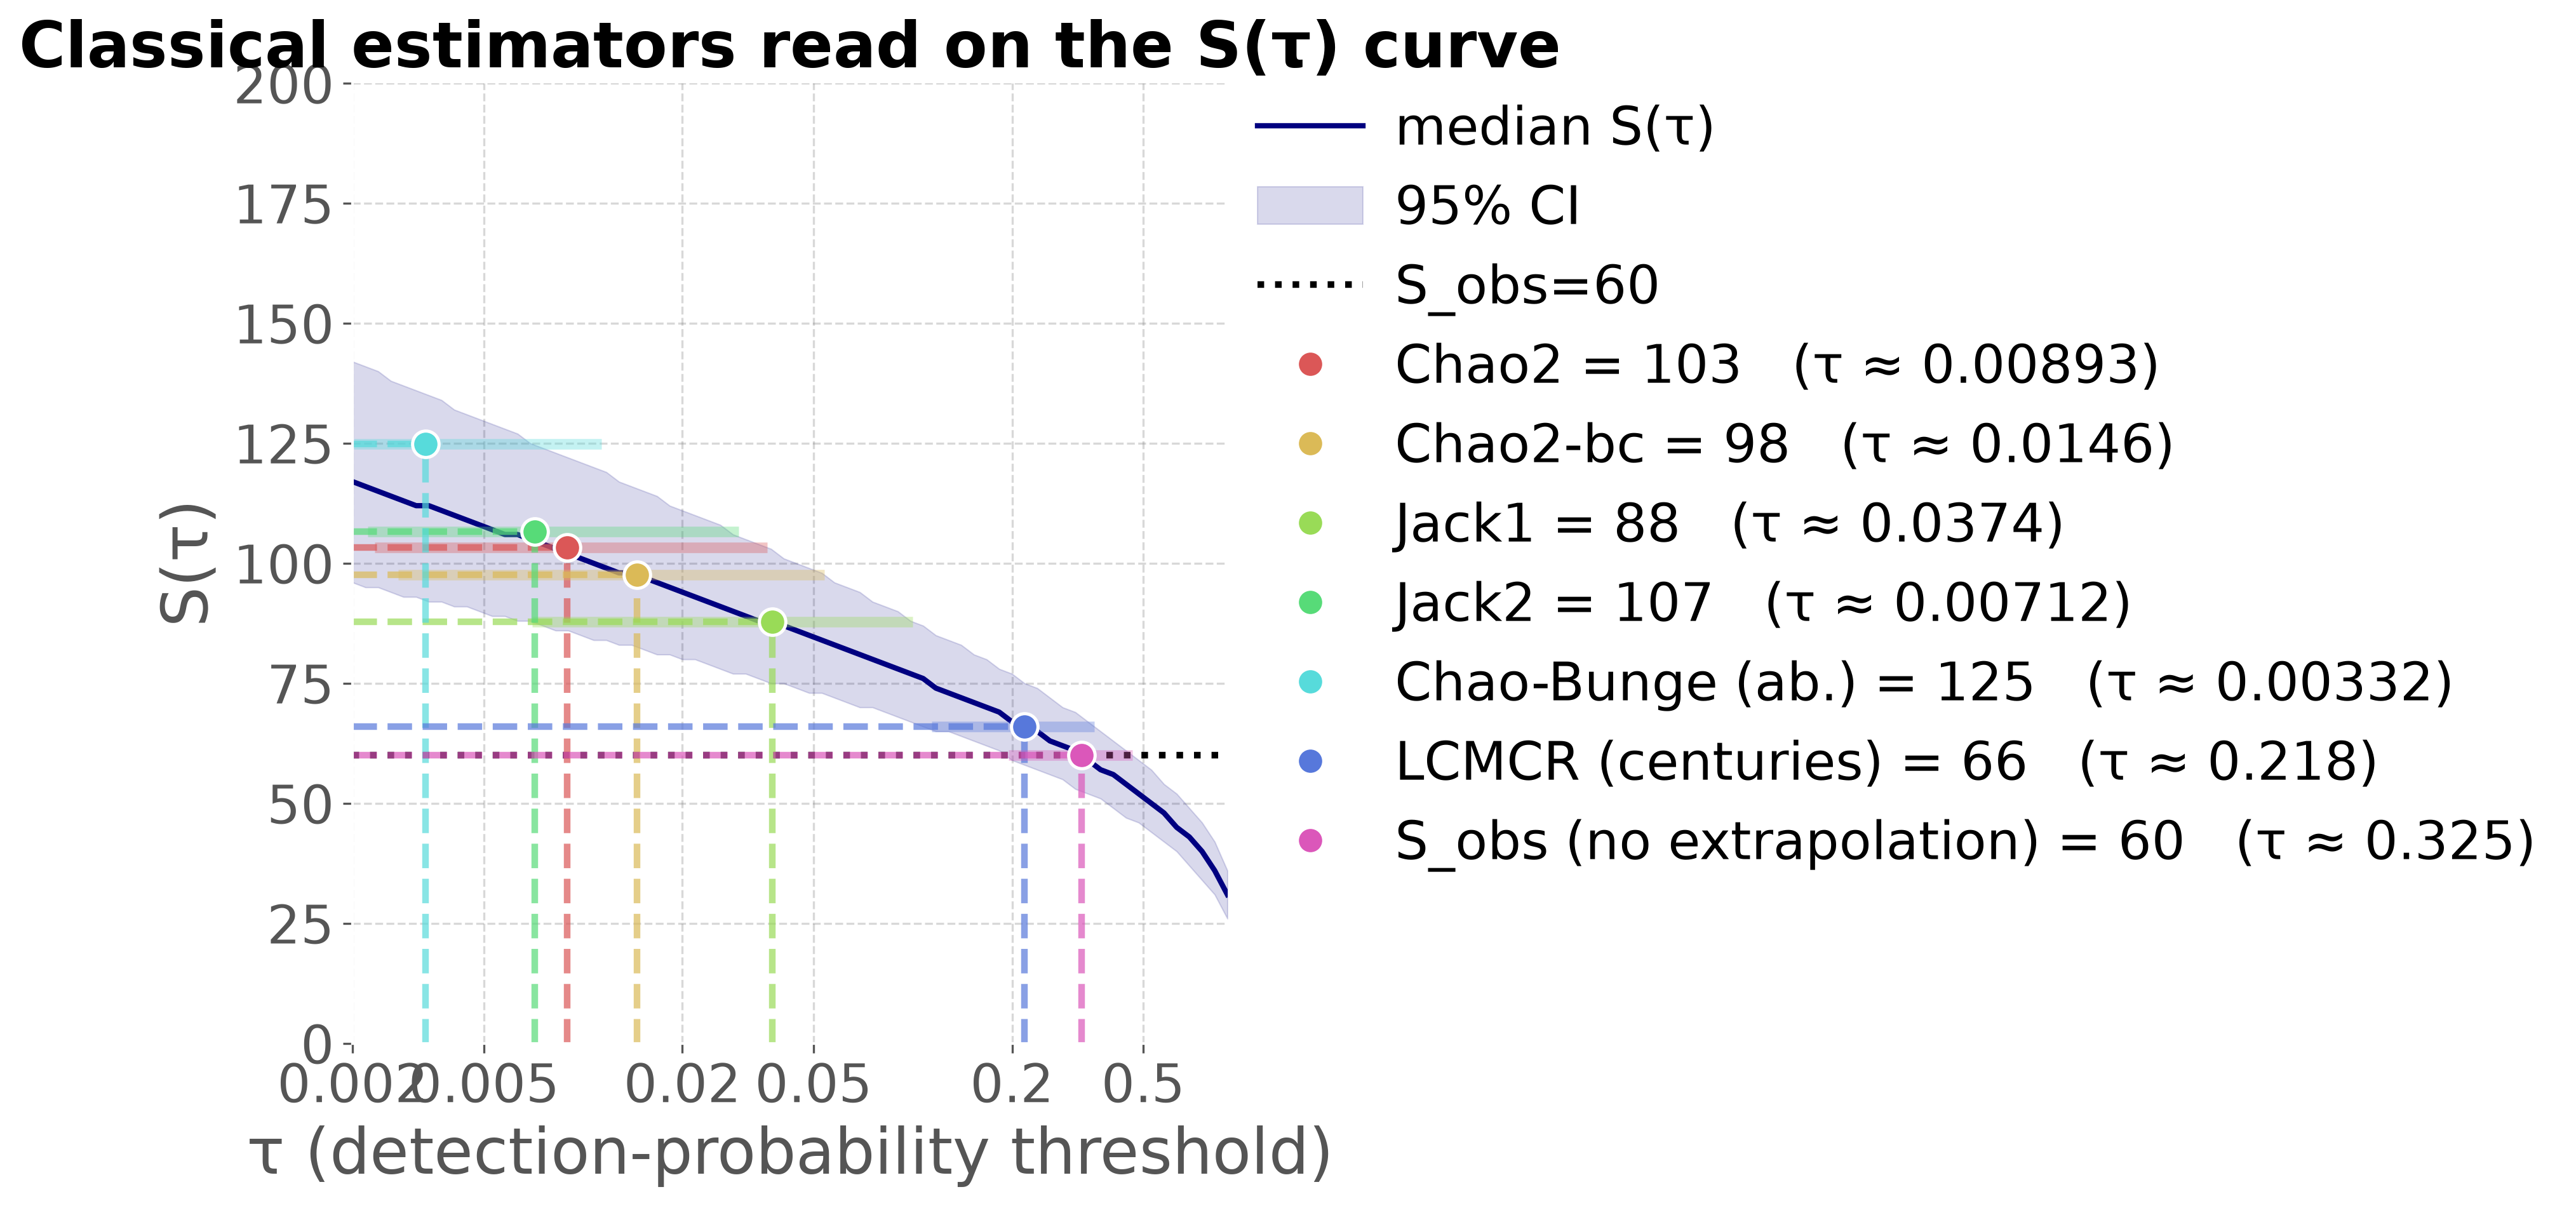

In [11]:
# Where does each classical estimate sit on OUR curve?
St_fine = S_tau(post, aux, list(TAU_FINE))
est_rows = implied_tau_table(est, TAU_FINE, St_fine, Sobs=Sobs,
                             extra={"LCMCR (centuries)": lcmcr_best,
                                    "Gamma-Poisson median S": (float(np.median(S_post)),) * 3})

plot_S_tau_estimators(TAU_FINE, St_fine, Sobs,
                      [r for r in est_rows if r[0] != "Chao-Bunge (inc.)"], ylim=200)
plt.show()

**The threshold each estimator implicitly assumes**, read against the Gamma–Poisson curve
(each $\tau$ inverted draw by draw, hence its own interval):

| estimator | $S$ estimate | implied $\tau$ | 95% CI on $\tau$ | under the lognormal |
|---|---|---|---|---|
| $S_{obs}$ (no extrapolation) | 60 | 0.33 | [0.20, 0.46] | 0.38 |
| LCMCR (centuries) | 66 | 0.22 | [0.11, 0.36] | 0.32 |
| Jack1 | 88 | 0.037 | [0.007, 0.100] | 0.17 |
| **Chao2** | **103** | **0.009** | [0.002, 0.036] | 0.11 |
| Jack2 | 107 | 0.007 | [0.002, 0.030] | 0.10 |
| Chao–Bunge (abundance) | 125 | 0.003 | [0.002, 0.011] | 0.064 |
| Gamma–Poisson median $S$ | 601 | *off grid* | — | — |

Because this model's $S(\tau)$ curve is far flatter at small $\tau$ than the lognormal's — 51 at
$\tau=0.5$ but still only 101 at $\tau=0.01$, where the lognormal already stands at 129 by
$\tau=0.05$ — the same estimates map onto *much smaller* thresholds here. The two models agree
almost exactly on where $S_{obs}$ and LCMCR sit (0.33 vs 0.38; 0.22 vs 0.32), and diverge by more
than an order of magnitude on Chao2 and Chao–Bunge. The lower bounds of 0.002 are the floor of
`TAU_FINE`, i.e. the inversion has run out of grid, not converged. And $S=601$ has no implied
threshold at all: it is off the grid entirely, so no threshold at which one would still be willing
to say "this work had a real chance of being cited" produces 601 works.

**What we conclude from this cell — and it is the argument of the whole notebook in one figure.**
The classical estimators and the Bayesian posterior are not two answers to one question; they are
readings of one curve at thresholds that differ by more than an order of magnitude. Three
consequences:

1. **The comparison between the two parametric families is a comparison of implied $\tau$.** The
   same Chao2 = 103 implies $\tau=0.11$ under the lognormal and $\tau=0.009$ here — a factor of
   twelve. That gap *is* the disagreement between the families about the low tail, expressed on the
   scale where it is legible; and note that it opens only *below* $\tau\approx0.2$, since the two
   agree on $S_{obs}$ and on LCMCR. It confirms that the disagreement lives exactly where the
   cross-tabulated PPC above says the Gamma fits worst (the rarity statistics $f_1$, $Q_1$).
2. **A number without a threshold cannot be checked.** $S=601$ is not refuted by Chao–Bunge's 125;
   it is simply an answer to a question about far fainter works, and neither the data nor the PPC
   speaks to it.
3. **The reportable results remain $S(0.5)=51$ [45, 58] and $S(0.2)=67$ [59, 77]** — the two
   thresholds the calibration study certifies, and both of them *above* the region where every
   classical estimator sits.

## Storing the latent $X_i,Y_j$

By default `gibbs` stores $X_i$, $X_u$ and $Y_\bullet$ (all that $S(\tau)$ needs), but not the
individual $Y_j$ of each source. To push the interpretation further — which sources transmit the
most, which works are the most "citable" — we need the individual effects on both sides. The flag
`store_latent=True` makes the sampler additionally keep the complete vector $Y$ at each retained
iteration; it is off by default because it multiplies the memory footprint of a long chain by $J$.

In [12]:
# store_latent=True additionally keeps the individual source efforts Y_j at each retained
# iteration (the default run stores only their sum Y_bullet, which is all S(tau) needs).
P, aux_l = gibbs(N, n_iter=60000, burn=20000, thin=10, seed=1, store_latent=True)
Xd, Yd = P['X'], P['Y']                 # draws: (n_draw, S_obs) and (n_draw, J)
Yp   = Yd.sum(1, keepdims=True)
w    = effort_shares(Yd)                # share of effort of each source  (scale-invariant)
mu   = Xd * Yp                          # E[number of citations] of text i (scale-invariant)
pdet = 1 - np.exp(-mu)                  # probability that a text of citability X_i is detected

**Derived quantities, invariant under the scale problem discussed above:**
- $w_j = Y_j / \sum_k Y_k$: the **share of transmission effort** of source $j$ — how much it
  contributes, relative to the other sources, to the total volume of citations. Unlike $Y_j$ alone,
  this ratio is identified (it does not depend on the scale factor $c$).
- $\mu_i = X_i \times \sum_j Y_j$: the **expected** number of citations of work $i$,
  $\mathbb E[N_{i\cdot}\mid X_i, Y] = X_i\sum_j Y_j$ — likewise scale-invariant.
- $p_{det,i} = 1-e^{-\mu_i}$: the probability, under the model, that work $i$ was detected at least
  once (the probability that a Poisson variable with mean $\mu_i$ is $\ge 1$).

Sources by share of transmission effort (posterior):
  Nonius | Compendiosa doctrina       35.1%  CI[33.1,37.2]  (753 cit.)
  Festus | De significatione verboru   7.2%  CI[ 6.2, 8.3]  (154 cit.)
  Priscien | Artis grammaticae         6.0%  CI[ 5.1, 7.1]  (129 cit.)
  Paulus Festus | De significatione    4.7%  CI[ 3.9, 5.7]  (101 cit.)
  Varron | De linguae latinae          3.9%  CI[ 3.1, 4.8]  (84 cit.)
  Aulu-Gelle | Noctes atticae          3.7%  CI[ 3.0, 4.5]  (79 cit.)
  Charisius | Artis grammaticae        3.5%  CI[ 2.7, 4.3]  (74 cit.)
  Servius | Commentarius in Vergilii   3.3%  CI[ 2.6, 4.0]  (70 cit.)
  top-1 = 35%   top-3 = 48%   Gini(effort) = 0.83

Most 'citable' texts (mu = E[number of citations]):
  Lucilius | Satires                       N=1122 -> mu=1115
  Q. Ennius | Annales                      N= 592 -> mu=589
  Cn. Naevius | Bellum punicum             N=  82 -> mu=82
  Livius Andronicus | Odyssia              N=  39 -> mu=39

Singletons (N_i.=1, 23 texts): median mu

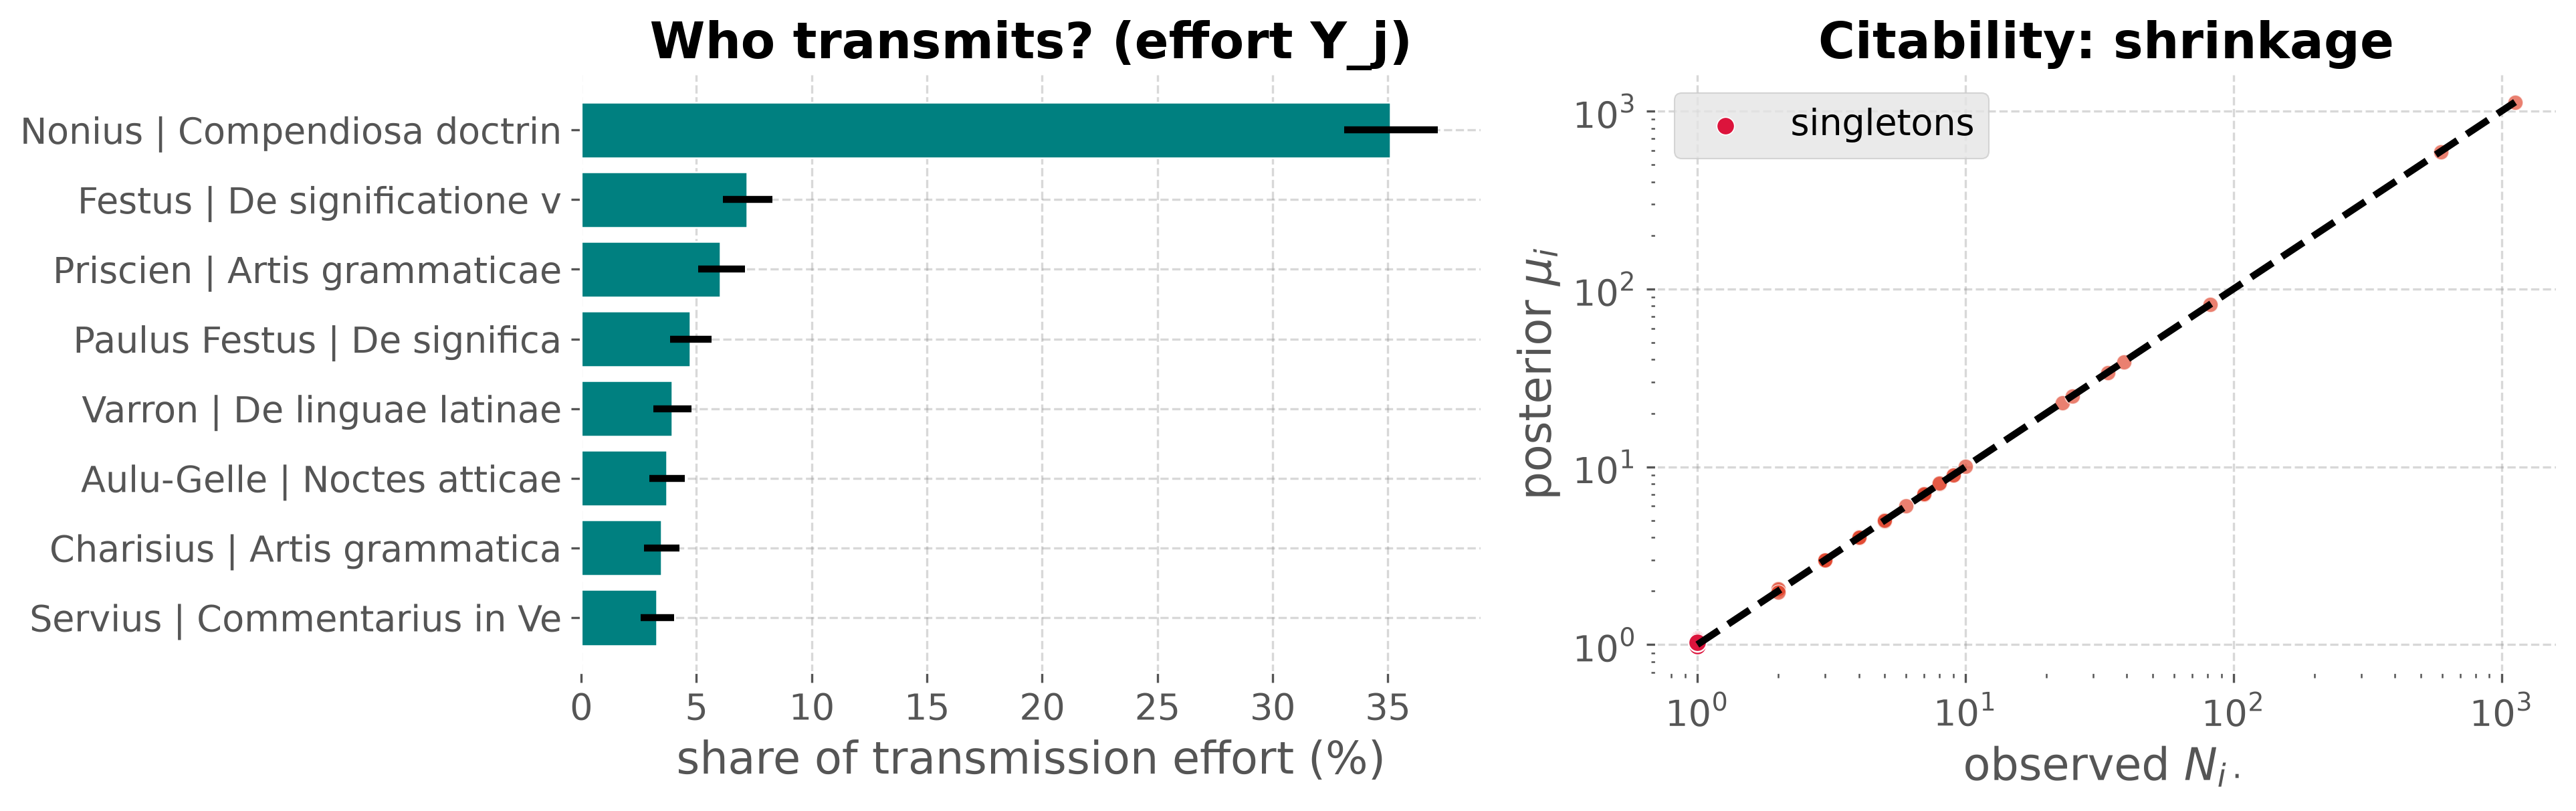

In [13]:
# ---------- EFFORT: concentration of the transmission ----------
order, wm, gini_effort = print_effort_table(cols, w, N, top=8)

# ---------- CITABILITY: shrinkage and detection probability ----------
Ni = N.sum(1)
print()
sing = print_citability_summary(rows, Ni, mu, pdet, top=4, pooled=True)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
plot_effort_bars(ax[0], cols, w, order, top=8)
plot_shrinkage(ax[1], Ni, mu.mean(0), sing)
plt.tight_layout(); plt.show()

**Results — who transmits?**

| source | share of effort | citations |
|---|---|---|
| Nonius, *Compendiosa doctrina* | **35.1 %** [33.1, 37.2] | 753 |
| Festus, *De significatione verborum* | 7.2 % | 154 |
| Priscian, *Ars grammatica* | 6.0 % | 129 |
| Paulus Festus, *De significatione* | 4.7 % | 101 |
| Varro, *De lingua Latina* | 3.9 % | 84 |
| Aulus Gellius, *Noctes Atticae* | 3.7 % | 79 |
| Charisius, *Ars grammatica* | 3.5 % | 74 |
| Servius, *Commentarius in Vergilii* | 3.3 % | 70 |

**Gini coefficient of the effort ≈ 0.83.** Transmission is highly concentrated: Nonius Marcellus
alone carries more than a third of the entire citation tradition of the corpus, followed by several
late lexicographers and grammarians. The figures agree closely with those of the companion lognormal
notebook (top-1 = 37 %, Gini = 0.84), which is reassuring: this part of the description is driven by
the observed margins and is therefore insensitive to the parametric family.

**Results — citability and shrinkage.**

| work | observed $N_{i\cdot}$ | posterior $\mu_i$ |
|---|---|---|
| Lucilius, *Satires* | 1122 | 1115 |
| Q. Ennius, *Annales* | 592 | 589 |
| Cn. Naevius, *Bellum Punicum* | 82 | 82 |
| Livius Andronicus, *Odyssia* | 39 | 39 |

**What the two figures show, and what we conclude from them.** The left panel (effort shares with
credible intervals) shows that the concentration is not an artefact of posterior uncertainty: the
intervals are narrow and Nonius is separated from the rest by a factor of five. The right panel
(log-log) illustrates **Bayesian shrinkage**: for well-attested works $\mu_i$ follows the diagonal
$\mu_i = N_{i\cdot}$ closely (the model merely confirms the observed counts), whereas for the
**singletons** (23 works with $N_{i\cdot}=1$, in red) it pulls the citability estimate downwards:
median $\mu \approx 0.72$ (< 1), with a **median detection probability of only 0.51**.

In other words, for half of the works known to us by a single citation, the model estimates that they
had about an even chance of remaining completely invisible. That figure is very close to the one
obtained by the Poisson-lognormal model on the same corpus (median $\mu$ 0.74, median $p_{det}$
0.41), which again shows that where the data speak the two models say the same thing. **This is the
concrete meaning of the whole exercise: our knowledge of archaic Latin literature sits, for a
substantial fraction of it, exactly at the detectability threshold.**

stat      observed  pred. med.  95% pred. interval  p Bayes
-- frequencies (citations per work) -----------------------
Sobs            60          58   [    39,     82]     0.94
f1              23          10   [     4,     19]     0.00  <-- MISFIT
f2               8           5   [     1,     11]     0.35
tot           2080        2124   [   875,   4602]     0.96
maxc          1122         340   [   122,   1010]     0.03  <-- MISFIT
-- incidences (distinct sources per work) -----------------
Q1              28          11   [     5,     20]     0.00  <-- MISFIT
Q2               9           6   [     2,     12]     0.37
maxsrc         101          65   [    36,    107]     0.09


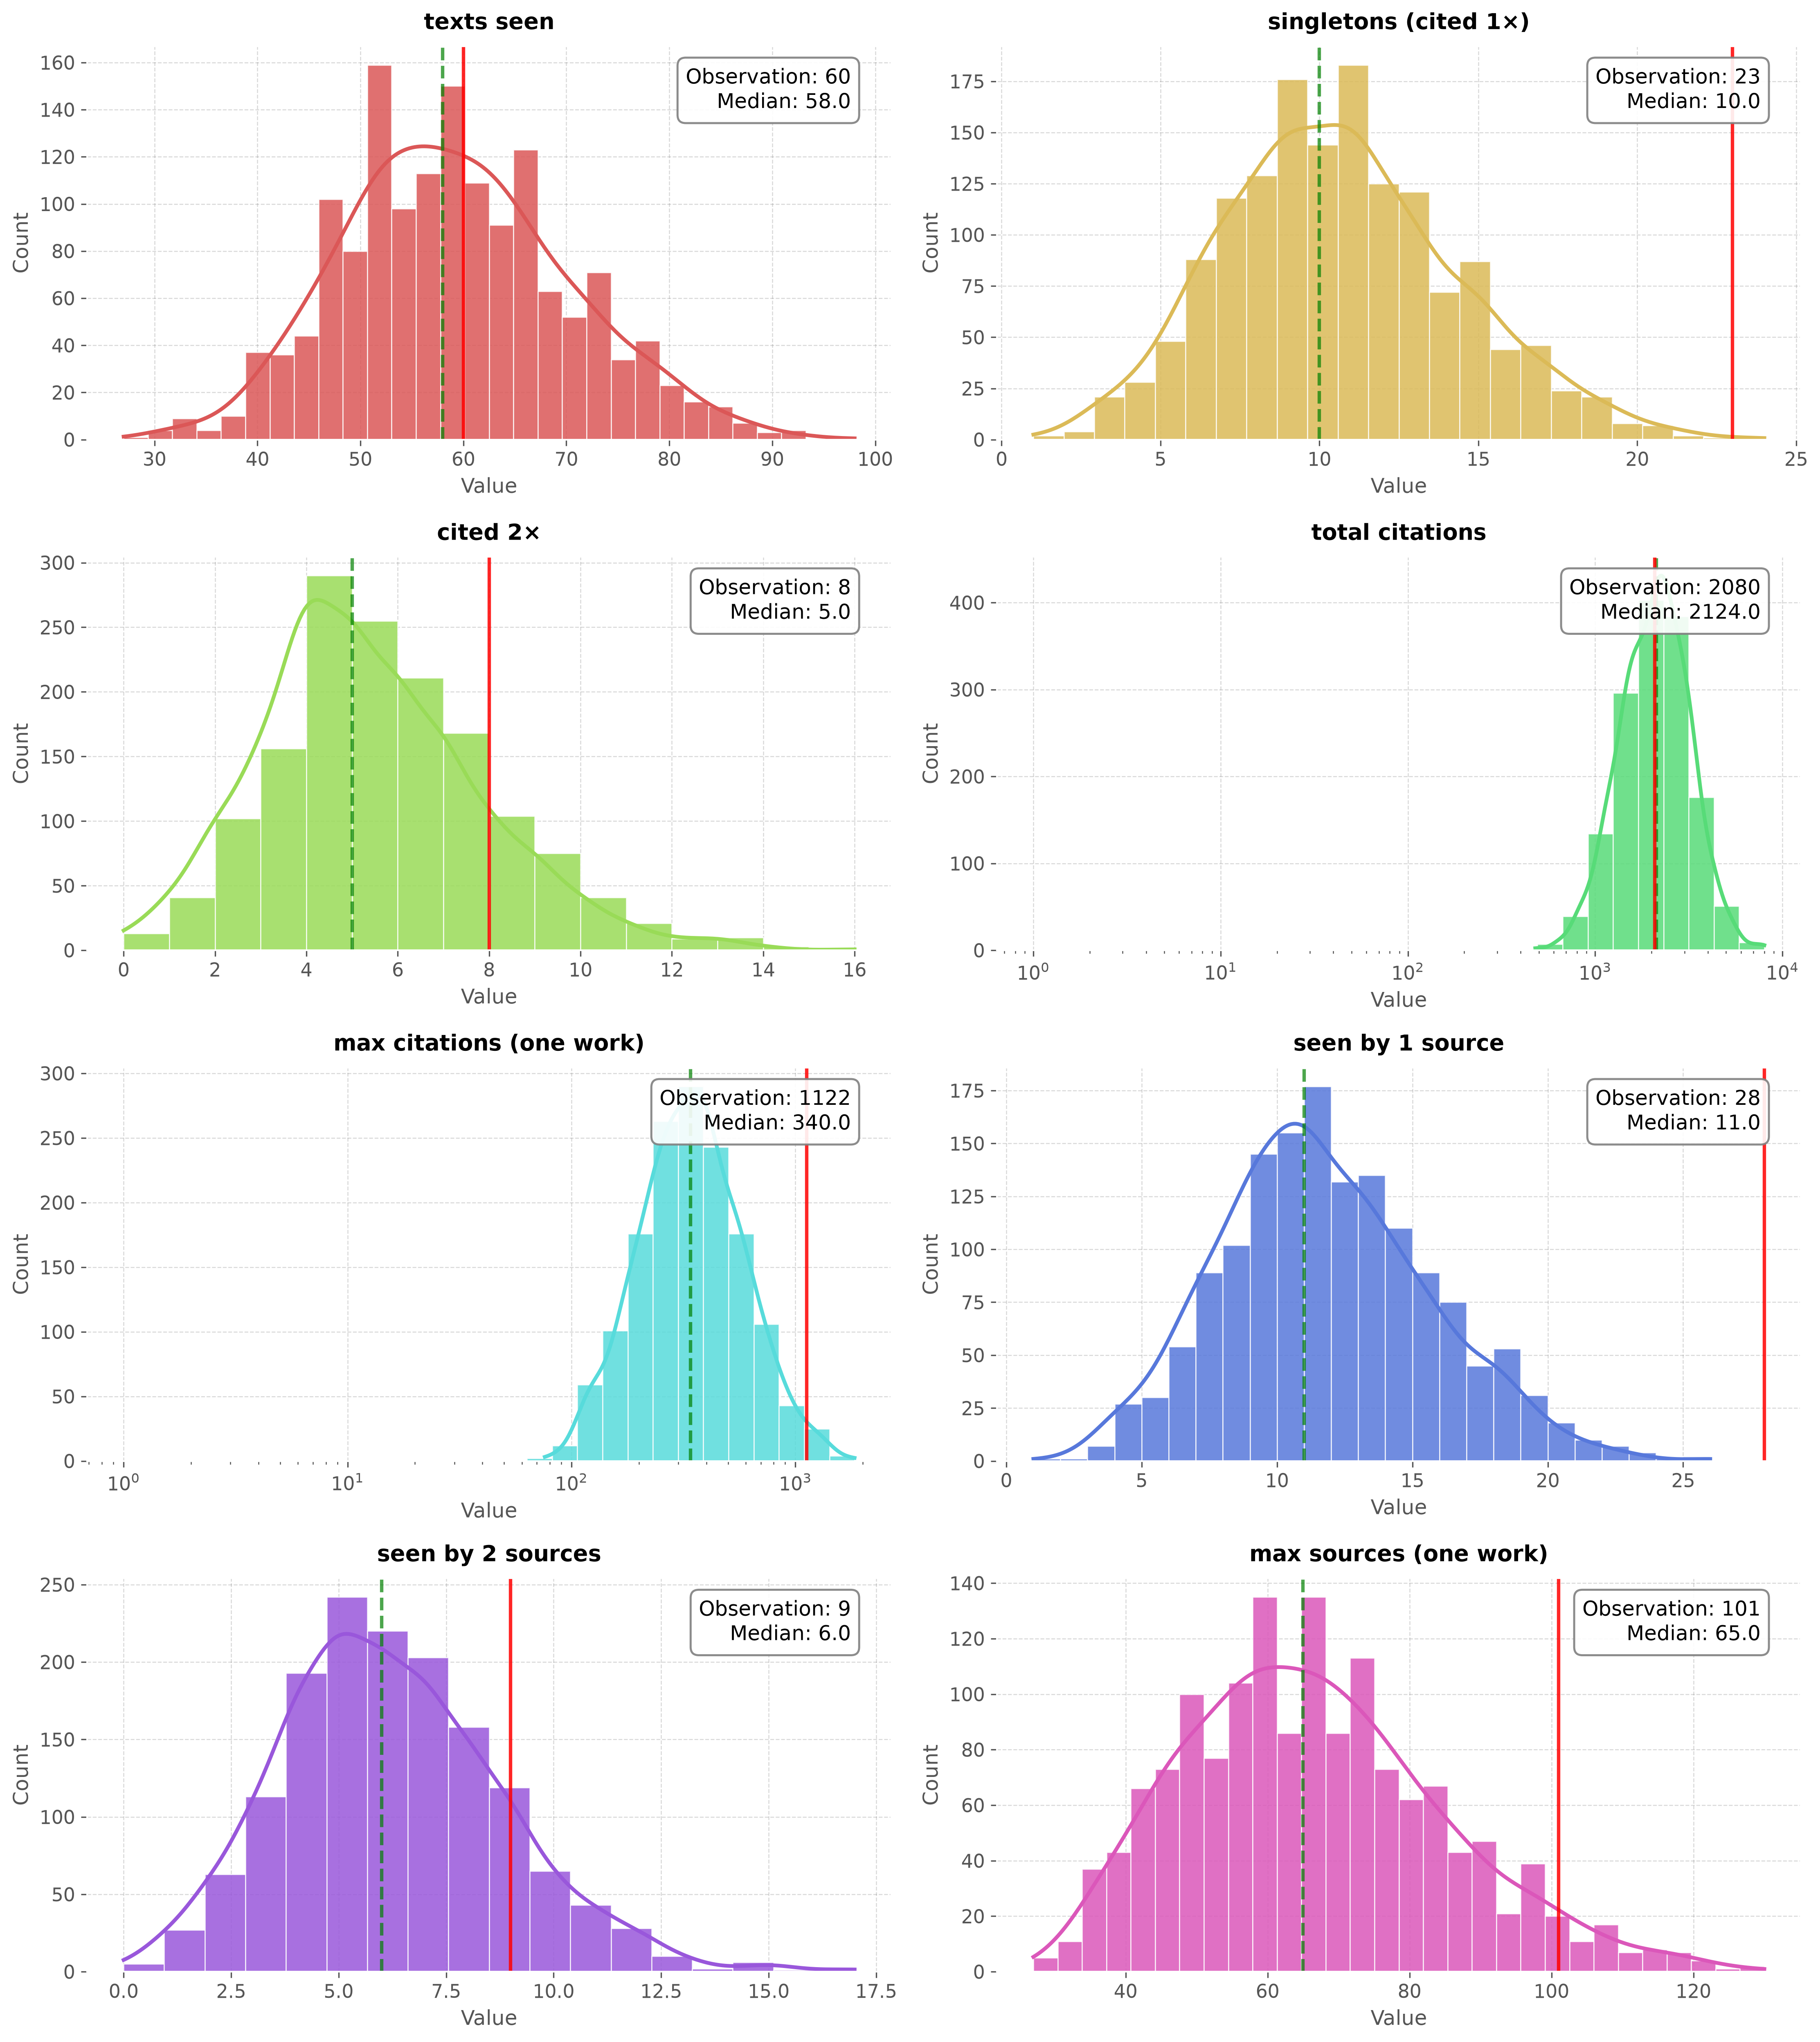

In [14]:
# ppc() is shared with the lognormal notebook (it dispatches on aux["family"]): for a large number
# of posterior draws it re-simulates a COMPLETE corpus -- a new S, new citabilities X for that new
# population of texts, while keeping the Y_j already inferred for the sources -- and compares the
# summary statistics with those of the corpus actually observed. It always returns the same eight
# statistics; they are all shown here (frequencies and incidences), and the same draws are reused
# by the cross-tabulated comparison at the end of the notebook.
obs_c, reps_g = ppc(P, aux_l, N, ndraw=1500, seed=0)
print_ppc_table(obs_c, reps_g)

plot_ppc_hists(obs_c, reps_g, STATS, log_keys=("tot", "maxc"), ncols=2)
plt.show()

**Posterior predictive check.** The principle: for a large number of posterior draws of the
parameters, we **re-simulate a complete corpus** (a new $S$, new citabilities $X$ for that new
population of texts — while keeping the $Y_j$ already inferred for the sources, which are fixed), and
compare the summary statistics of the simulated corpus with those of the corpus **actually
observed**. If the model is adequate, the observed corpus should look like a "typical" draw from it
(the observed statistic near the centre of the predictive distribution, a Bayesian $p$-value neither
close to 0 nor to 1).

**Results:**

| statistic | observed | predictive median | 95% predictive interval | $p$ Bayes |
|---|---|---|---|---|
| texts seen ($S_{obs}$) | 60 | 58 | [39, 82] | 0.94 |
| singletons ($f_1$) | 23 | 10 | [4, 19] | **0.00 — misfit** |
| cited twice ($f_2$) | 8 | 5 | [1, 11] | 0.35 |
| max citations | 1122 | 340 | [122, 1010] | **0.03 — misfit** |
| total citations | 2080 | 2124 | [875, 4602] | 0.96 |

**What the four histograms show, and what we conclude from them.** In the panels for $S_{obs}$ and
$f_2$ the red line (observed value) sits comfortably inside the predictive mass; in the panels for
$f_1$ and `maxc` it sits at or beyond the edge. **The model passes on $S_{obs}$, $f_2$ and the total
number of citations, and fails clearly on two points: the number of singletons and the maximal
citation count.** The real corpus has more than **twice** as many singletons as the model typically
predicts, and one work (Lucilius) concentrating far more citations (1122) than the Gamma law fitted
to the whole corpus can reproduce (predictive median ~340, with the 95 % interval reaching only
1010) — even though Ennius (592 citations) is in the corpus and might have widened that predictive
tail.

**What this means.** A single $\text{Gamma}(\alpha,\beta)$ law, with a very small $\alpha$, must
simultaneously explain (i) a mass of singletons with citability near 0 and (ii) extreme outliers
(Lucilius, Ennius) — a structural trade-off the Gamma shape cannot satisfy at both ends: by pulling
$\alpha$ down to capture the extreme, the model underestimates the number of very low-frequency
works. Concretely, the real corpus is probably **not homogeneous** in the sense of the model:
Lucilius and Ennius (and to a lesser extent Naevius and Livius Andronicus) are a case apart — school
canon, obligatory reference for the grammarians — rather than a "normal" draw of extreme citability
from a single homogeneous population of texts. A natural extension would be to treat these few
canonical works separately (a two-component mixture, or removal and separate treatment) rather than
letting them weigh on the estimation of a single citability distribution for the whole corpus — which,
as we have seen, is also what pushes $S_0$ (and hence the non-identifiable $S$) towards very high and
very uncertain values. $S(\tau)$, by contrast, is largely indifferent to this misfit (see the leverage
test above).

Lognormal column: recomputed from ppc_lognormal.npz (identical p-value convention)

statistic                  obs |  Gamma med.      p |  LNorm med.      p | verdict
----------------------------------------------------------------------------------
-- FREQUENCIES (citations/work) --------------------------------------------------
texts seen                  60 |          58   0.94 |          62   0.91 | both OK
singletons (cited 1×)       23 |          10   0.00 |          23   1.00 | Gamma alone misfits
cited 2×                     8 |           5   0.35 |           8   1.00 | both OK
total citations           2080 |        2124   0.96 |        1426   0.75 | both OK
max citations (one work)  1122 |         340   0.03 |         518   0.67 | Gamma alone misfits
-- INCIDENCES (sources/work) -----------------------------------------------------
seen by 1 source            28 |          11   0.00 |          25   0.77 | Gamma alone misfits
seen by 2 sources            9 |           6   0.3

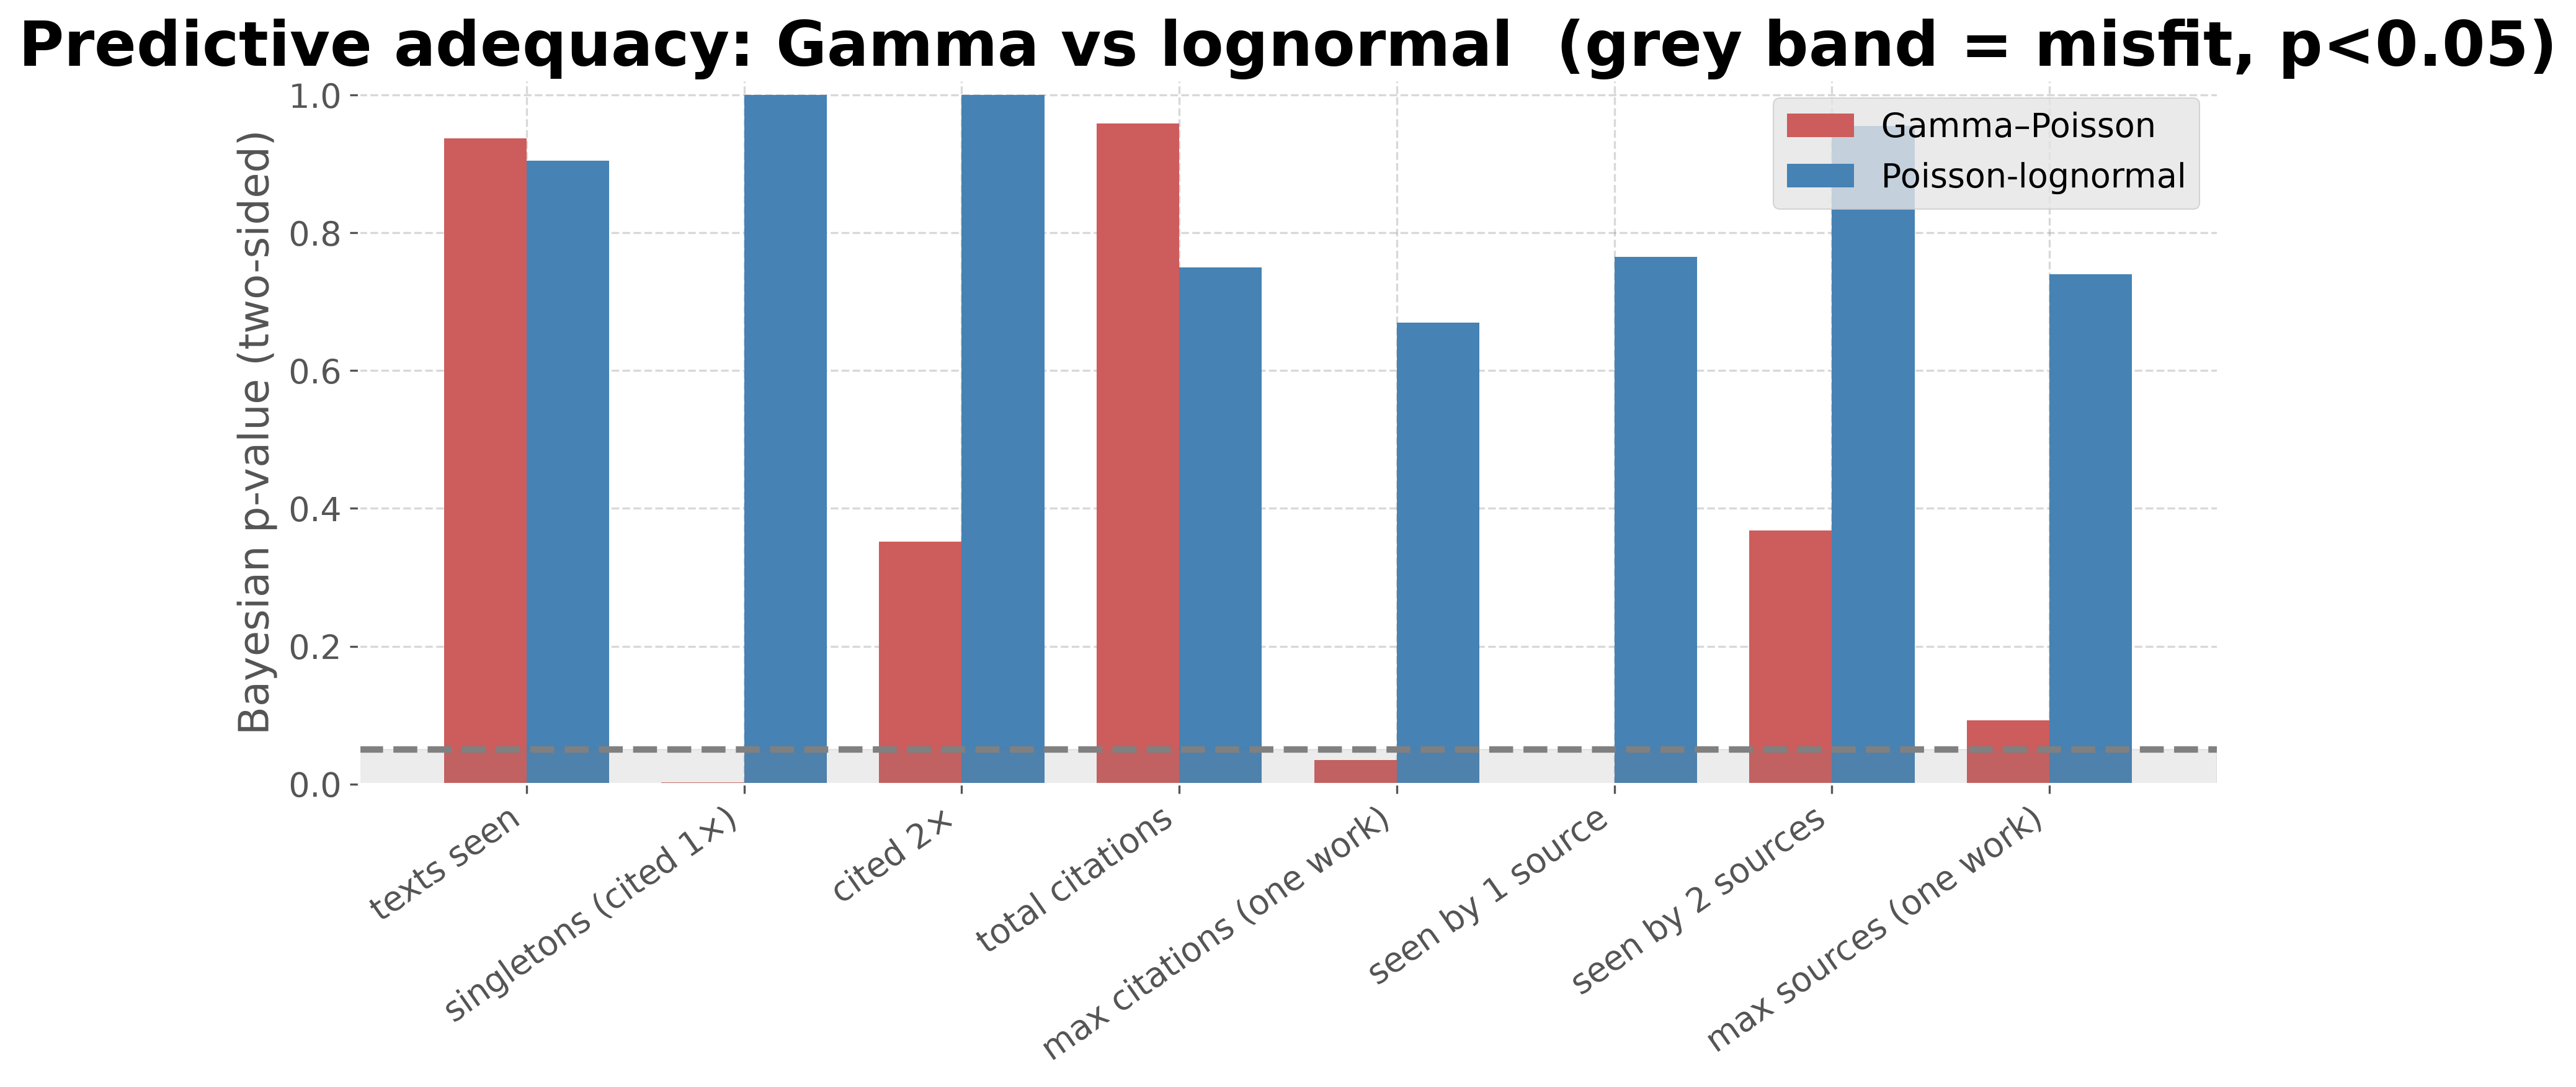

In [15]:
# ============================================================================
#  Formal comparison of Gamma-Poisson and Poisson-lognormal: cross-tabulated PPC
# ----------------------------------------------------------------------------
#  Each notebook runs its own posterior predictive check. Here we place them SIDE BY
#  SIDE, on EXACTLY the same summary statistics and with the same two-sided Bayesian
#  p-value convention -- which is now guaranteed by construction, since both call
#  lost_texts.corpus_stats() and lost_texts.pbayes(). Two families of statistics:
#    * FREQUENCIES: number of citations per work  (Sobs, f1, f2, total, max)
#    * INCIDENCES : number of distinct sources per work (Q1, Q2, max sources)
#      -- this is the rarity information that Chao2 and the incidence jackknives exploit.
#  The Gamma draws are those already computed by ppc() above (same seed, same draws);
#  the lognormal ones are loaded from the draws exported by Poisson_lognormal.ipynb
#  ("ppc_lognormal.npz"); failing that, we fall back on the published values of that
#  notebook, which serve only as a reference point.
# ----------------------------------------------------------------------------
REF_LN = {'Sobs': (62, 0.91), 'f1': (23, 1.00), 'f2': (8, 1.00), 'tot': (1426, 0.75),
          'maxc': (518, 0.67), 'Q1': (25, 0.77), 'Q2': (10, 0.95), 'maxsrc': (75, 0.74)}
ln, ln_src = load_lognormal_ppc(obs_c, "ppc_lognormal.npz", fallback=REF_LN)

def verdict(pg, pl):
    if pg >= 0.05 and pl >= 0.05: return 'both OK'
    if pg >= 0.05:                return 'lognormal alone misfits'
    if pl >= 0.05:                return 'Gamma alone misfits'
    return 'both misfit'

print(f"Lognormal column: {ln_src}\n")
hdr = f"{'statistic':24s}{'obs':>6s} | {'Gamma med.':>11s}{'p':>7s} | {'LNorm med.':>11s}{'p':>7s} | verdict"
print(hdr); print('-' * len(hdr))
for fam, keys in [("FREQUENCIES (citations/work)", ['Sobs', 'f1', 'f2', 'tot', 'maxc']),
                  ("INCIDENCES (sources/work)", ['Q1', 'Q2', 'maxsrc'])]:
    print(f"-- {fam} " + '-' * max(0, len(hdr) - len(fam) - 4))
    for k in keys:
        mg, pg = np.median(reps_g[k]), pbayes(reps_g[k], obs_c[k])
        ml, pl = ln[k]
        print(f"{STAT_LABELS[k]:24s}{obs_c[k]:6d} | {mg:11.0f}{pg:7.2f} | {ml:11.0f}{pl:7.2f} | {verdict(pg, pl)}")

# --- p-values side by side ---
pg_all = {k: pbayes(reps_g[k], obs_c[k]) for k in STATS}
pl_all = {k: ln[k][1] for k in STATS}
ax = plot_ppc_pvalues(pg_all, pl_all, "Gamma–Poisson", "Poisson-lognormal")
ax.set_title("Predictive adequacy: Gamma vs lognormal  (grey band = misfit, p<0.05)")
plt.tight_layout(); plt.show()

### Formal comparison of Gamma-Poisson and Poisson-lognormal (cross-tabulated PPC)

Both notebooks apply their own posterior predictive check to the **same corpus**. Here we confront
them on **the same statistics** with **the same two-sided Bayesian $p$-value**, distinguishing the
*frequencies* (citations per work) from the *incidences* (distinct sources per work — the rarity
information that Chao2 and the incidence jackknives use). The Gamma PPC above looked only at frequencies; it is
re-run here capturing incidences **as well**, so that the confrontation bears on exactly the same set
of statistics as the lognormal notebook.

| statistic | observed | Gamma med. | $p_{\text{Gamma}}$ | LNorm med. | $p_{\text{LNorm}}$ | verdict |
|---|---|---|---|---|---|---|
| *Frequencies* |||||||
| texts seen ($S_{obs}$) | 60 | 58 | 0.94 | 62 | 0.91 | both OK |
| singletons ($f_1$) | 23 | 10 | **0.00** | 23 | 1.00 | **Gamma alone misfits** |
| cited twice ($f_2$) | 8 | 5 | 0.35 | 8 | 1.00 | both OK |
| total citations | 2080 | 2124 | 0.96 | 1426 | 0.75 | both OK |
| max citations | 1122 | 340 | **0.03** | 518 | 0.67 | **Gamma alone misfits** |
| *Incidences* |||||||
| seen by 1 source ($Q_1$) | 28 | 11 | **0.00** | 25 | 0.77 | **Gamma alone misfits** |
| seen by 2 sources ($Q_2$) | 9 | 6 | 0.37 | 10 | 0.95 | both OK |
| max sources (one work) | 101 | 65 | 0.09 | 75 | 0.74 | both OK |

**What the figure shows, and what we conclude from it.** The bar chart puts the eight $p$-values side
by side, with the misfit region (p < 0.05) shaded. Three red bars fall into it and no blue one does.

- On the **central** statistics — texts seen, doubletons, total citations — both models pass, which
  explains their agreement on $S(\tau)$, an estimand governed by the body of the distribution.
- It is on the statistics of **rarity and of the extreme** that they separate. **The Gamma fails on
  three of them**: the number of singletons ($f_1$, $p=0.00$: it predicts about half as many as
  observed), the maximal citation count of Lucilius ($p=0.03$: predictive median ~340 against 1122
  observed) and, revealed by adding the incidences, the **number of works seen by a single source**
  ($Q_1$, $p=0.00$: 11 predicted against 28 observed). A single $\text{Gamma}(\alpha,\beta)$ law
  cannot simultaneously produce a mass of nearly invisible works *and* extremes such as Lucilius.
- **The lognormal reproduces all eight statistics** (no $p<0.05$), frequencies *and* incidences. Its
  heavy-tailed citability ($s_x\approx3.7$) generates as many singletons and single-source works as
  the real corpus, as well as the Lucilius spike.

**Conclusion, with one caveat.** As an adequacy criterion the cross-tabulated PPC **decides in favour
of the lognormal**: it strictly dominates the Gamma (it passes wherever the Gamma passes, and also
where the Gamma fails). That is consistent with the more pronounced non-identifiability of $S$ under
the Gamma (leverage +148 % against +39 % for the lognormal, coverage 50 % against 83 %). The caveat
is that the lognormal's passes on the *volume* statistics (total, max) are obtained with predictive
intervals spanning two orders of magnitude, so on those two lines the test has almost no power: the
lognormal is "not contradicted" there rather than "validated". The lognormal's advantage rests
squarely on the rarity statistics ($f_1$, $Q_1$), where the test does have power.

**And the reassuring part: this disagreement does not contaminate $S(\tau)$.** The two models agree
exactly on $S(0.5)$ (51 vs 51) and closely on $S(0.75)$ (40 vs 37), because that estimand depends
only on the body of the distribution — precisely the region where the two families coincide. The
choice of estimand therefore matters more than the choice of family; but if one also wants a
generative model faithful to the corpus in its details (rarity, extremes), the lognormal is the
better of the two.

> *Reproducibility.* The lognormal column is loaded from `ppc_lognormal.npz` when that file is
> present (draws exported by `Poisson_lognormal.ipynb`, with $p$-values recomputed here under an
> identical convention); otherwise the cell falls back on the published values of that notebook,
> reproduced in the table above.

### Threshold richness on a single figure: lognormal vs Gamma-Poisson

The two families are compared statistic-by-statistic above; here the two $S(\tau)$ curves
themselves are overlaid on the same axes, both computed on the canonical grid `TAU_GRID` (defined
once in `lost_texts.py` and shared by the two notebooks) so that they line up exactly. This is the
single figure that makes the argument of the whole comparison visible at a glance: the two curves
coincide where $\tau$ is not too small, and separate only as $\tau\to0$, into the region neither
model can constrain.

Lognormal curve: recomputed from stau_lognormal.npz


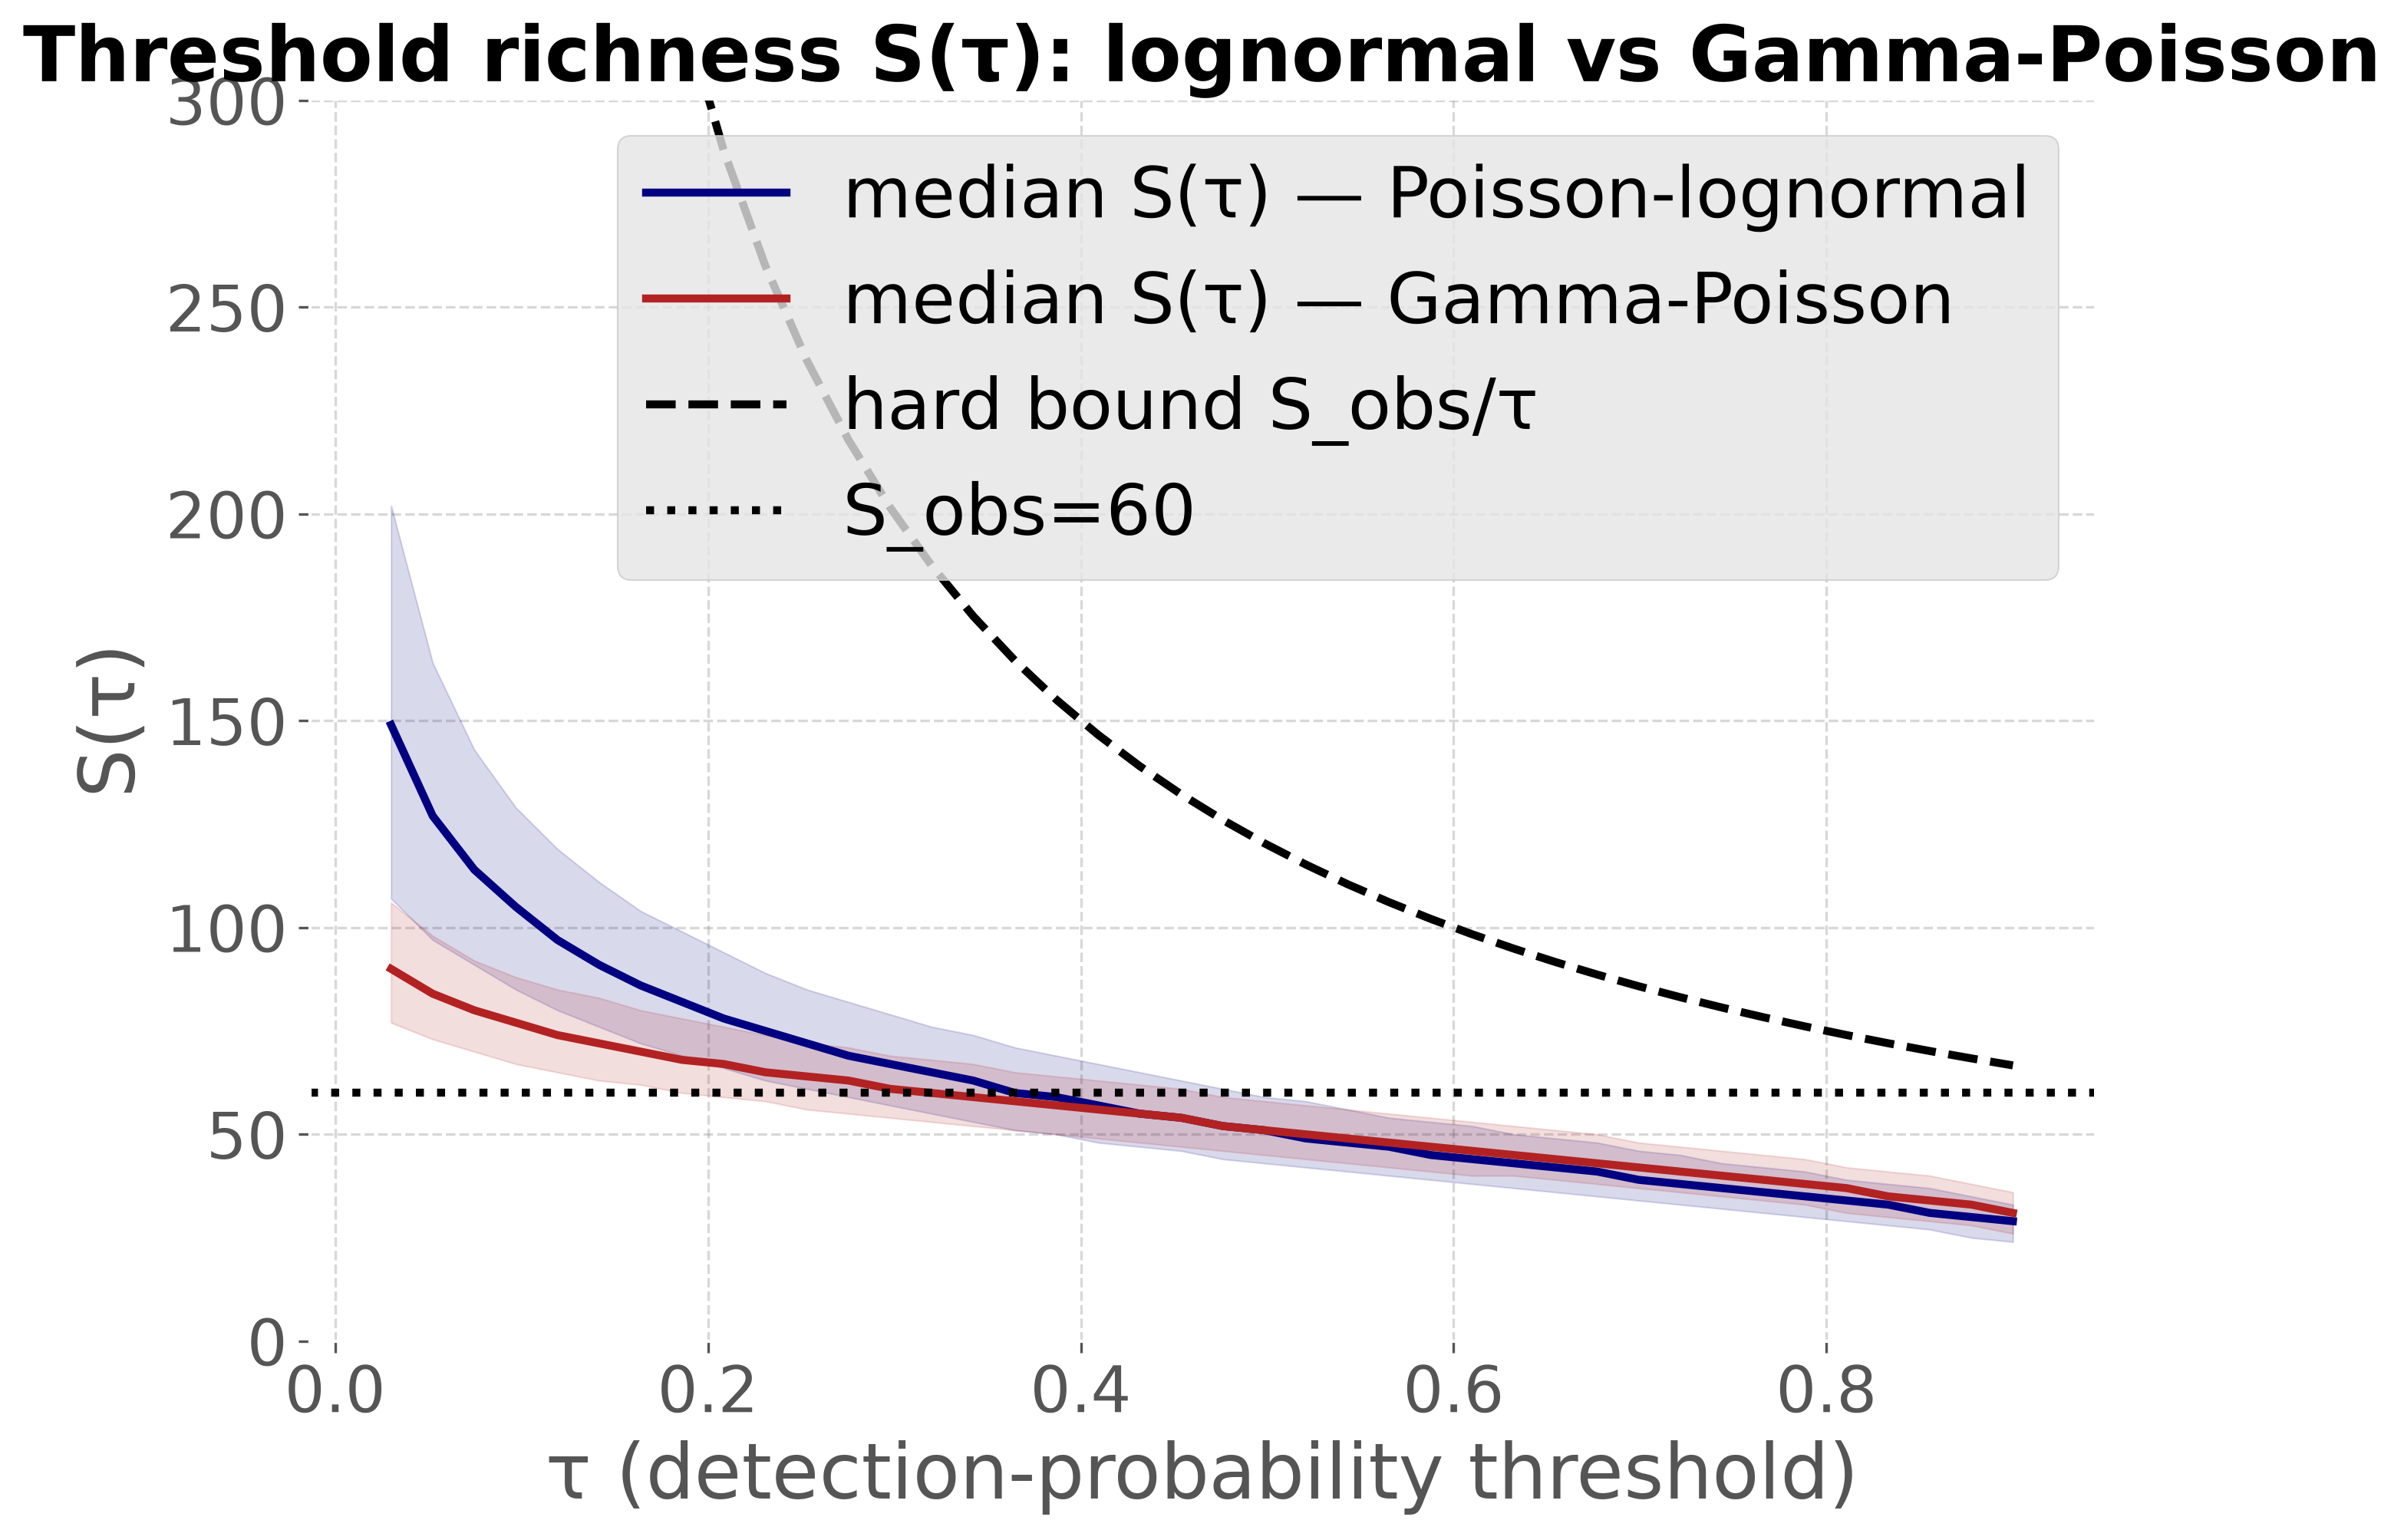

In [16]:
ln_tau, ln_med, ln_lo, ln_hi, ln_src = load_S_tau_curve("stau_lognormal.npz")
print(f"Lognormal curve: {ln_src}")

plot_S_tau_comparison((ln_tau, ln_med, ln_lo, ln_hi), None, TAU_GRID, St_gp, Sobs, ylim=300)
plt.show()

## Summary

- **Same corpus as the companion notebook.** Both notebooks call the same `load_corpus` in
  `lost_texts.py` (anonymous works retained, anonymous citing sources distinguished by citing
  work): **60 observed works × 167 sources, 2080 citations**. Every figure below is therefore
  directly comparable with the lognormal notebook, statistic by statistic.
- **The sampler is correctly implemented and well calibrated in a well-specified regime** (recovery
  study plus 30 simulations: coverage 90–100 %, median relative error on $S$ ≈ 1.8 %). It is also
  converged: with 200,000 iterations per chain (half discarded, thinned by 10) every
  $\hat R_\infty$ is at most 1.004, against a 5 % threshold of 1.031. The diagnostic is the local
  $\hat R_\infty$ of Moins et al. (2023), a supremum over quantiles of $\hat R$ applied to indicator
  variables, which — unlike the traditional Gelman–Rubin $\hat R$ — also detects chains that agree on
  the first two moments while disagreeing on the tail, the relevant failure mode for the
  heavy-tailed posteriors of $\Lambda$, $\pi_0$ and $S$.
- **On the real corpus** it reveals extreme heterogeneity on both sides: works (citability
  $\alpha\approx0.020$; Lucilius and Ennius together account for 82 % of the citations) and sources
  (effort: Nonius Marcellus ≈ 35 % of the citations, Gini ≈ 0.83).
- **$S$ (the total number of works) is not identifiable.** The point estimate (median $S \approx 601$,
  95 % CI [209, 2412]) is **highly sensitive to the prior** on the shape $\alpha$ ($S$ ranges from 213
  to 540 across reasonable priors), and two independent empirical checks confirm it spectacularly: in
  a regime matched to the real data its 95 % intervals cover the truth only 50 % of the time, with a
  median relative error of 77 %, and a single extreme observation shifts it by **+148 %**.
- **$S(\tau)$ — the number of works with at least probability $\tau$ of being detected — repairs the
  problem.** It is a bounded functional (the hard bound $S_{obs}/\tau$ holds without any model), well
  calibrated (100 % coverage with a relative error of 2–7 % at $\tau=0.5$ and $\tau=0.2$) and
  insensitive to extreme values ($-1.5$ % and $+5.4$ %). The estimands retained for this corpus:
  **$S(0.5)\approx51$, 95% CI [45, 58]**, and **$S(0.2)\approx67$, 95% CI [59, 77]**.
- **The model fails the predictive check** on two key statistics (singletons and maximal citation
  count), and on a third once incidences are included ($Q_1$) — a sign that the assumption of a
  homogeneous citability population (a single Gamma law) is probably too simple for this corpus, in
  which a few "canonical" works (Lucilius, Ennius) behave differently from the rest. The
  cross-tabulated check with the lognormal model makes this formal, and decides in favour of the
  lognormal.
- **The classical estimators sit far below $S$, and reading them at their implicit threshold says
  why.** Chao1 is not reported, being inappropriate to a multiple-list design; **Chao2 = 103**
  [76, 174], the incidence jackknives give 88 and 107, and **Chao–Bunge — the non-parametric
  estimator derived under the very gamma-mixed Poisson law fitted here — gives 125** after the
  cut-off correction its authors prescribe. Without that correction it is simply *undefined* on this
  corpus ($\hat\theta=-7.6$): the same single observation that moves $S$ by $+148\,\%$ breaks the
  matched non-parametric estimator outright. That two methods committed to the same family answer
  125 and 601 is the non-identifiability of $S$ seen from a second direction.
- **LCMCR, re-run on the current corpus, is degenerate.** Manrique-Vallier's latent-class
  capture–recapture model (`lcmcr_check.py`) returns $N=60=S_{obs}$ with the 167 sources as lists
  and $N=66$ [61, 75] with 13 century lists, insensitive to the truncation and to the DP prior:
  with $J=167$ the all-zero probability $\prod_j(1-\lambda_j)$ is pinned at zero by arithmetic
  rather than by evidence. It marks the floor of what incidence patterns alone support, and this
  notebook's curve places that floor at $\tau=0.22$.
- **Because this model's curve is flat at small $\tau$, the same estimates imply much lower
  thresholds here than under the lognormal** — Chao2 = 103 means $S(0.11)$ there but
  $S(0.009)$ here, and $S=601$ is off the grid altogether. That gap is exactly the
  disagreement between the two families about the low tail, expressed on a scale one can read.

### External benchmark: comparison with the Poisson-lognormal model

The companion notebook (`Poisson_lognormal.ipynb`) analyses exactly the same corpus with a
Poisson-lognormal parametrisation (citability and effort lognormal rather than Gamma), and introduces
the same estimand $S(\tau)$ for the same reasons. **On $S$ the two models diverge** (601 here against
about 254 for the lognormal at the same prior scale), and the non-identifiability is more pronounced
under the Gamma (leverage $+148$ % against $+39$ %; coverage 50 % against 83 %). **On $S(\tau)$, at
thresholds that are not too small, they agree closely** — $S(0.5)$: 51 vs 51; $S(0.75)$: 40 vs 37 —
the agreement loosening as $\tau$ falls ($S(0.2)$: 67 vs 79), exactly as expected if the disagreement
lives in the low tail. This convergence, once the estimand is corrected, is the strongest argument
for the robustness of the conclusions common to the two notebooks: what matters is not the choice
between Gamma and lognormal, but the choice of estimand.

**Directions for improvement suggested by these results:**

1. Treat the few "canonical" works (Lucilius, Ennius, Naevius, Livius Andronicus) with a more
   flexible citability mixture (for instance a two-component mixture, or a distribution with a
   heavier tail than the Gamma), rather than letting them determine the shape of the whole
   distribution.
2. Continue reporting $S(\tau)$ rather than $S$ as the principal richness estimand, documenting
   explicitly the choice of $\tau$ and its hard bound $S_{obs}/\tau$.
3. Look elsewhere than capture–recapture for an independent benchmark. LCMCR is degenerate on this
   design (see the comparison section above), so it provides a floor rather than a rival estimate;
   the benchmark worth pursuing is the unseen-species literature applied to premodern literature
   (Karsdorp & Kestemont, *Science* 2022).
4. Test the sensitivity of every result to the column convention (`col_scenario` 1, 2 and 3), which
   changes the number of "detectors" by a factor of more than two and on which all incidence-based
   quantities ($Q_1$, $Q_2$, jackknife, effort shares) directly depend.